---
---

# DS-3002 Data Mining - Assignment 04


**Fatima Tu Zahra**

**23i-2616**

**BDS-6B**

**Spring-2026**

---
---


# Imports


In [1]:
!pip install tensorflow


In [2]:
import pandas as pd
import numpy as np
from scipy import stats

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.seasonal import seasonal_decompose
from scipy.spatial.distance import cdist
from tslearn.metrics import dtw

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt
from sklearn.tree import _tree
from sklearn.model_selection import cross_validate
from tensorflow.keras.datasets import mnist
import zipfile
import os
import urllib.request

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

from sklearn.metrics import roc_auc_score
from ucimlrepo import fetch_ucirepo 




I0000 00:00:1778002545.543450   36826 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1778002545.907079   36826 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1778002547.212174   36826 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1778002547.214327   36826 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.



## Scenario

CardioAI Labs is a fictional health-tech startup building decision-support tools for cardiologists at community hospitals. The clinic environment is intentionally constrained: no dedicated data team, ordinary office hardware, and a requirement that models train in minutes, not hours.

The project covers four technical areas:

- **Unsupervised learning** to discover hidden patient subgroups before labels are used.
- **Bagging and boosting** to build robust ensemble classifiers for heart disease prediction.
- **ANN / SLP / MLP** models for tabular heart disease data.
- **CNN** models for handwritten digit recognition on a MNIST subset.
- **Local front-end** dashboard for the best heart disease model.



## Datasets

### Dataset 1: UCI Heart Disease (Cleveland subset) - used in Pre, A, B, C, and E

| Field | Detail |
|---|---|
| Name | Heart Disease Dataset (Cleveland subset) |
| Source | UCI Machine Learning Repository |
| Direct URL | https://archive.ics.uci.edu/dataset/45/heart+disease |
| File to use | processed.cleveland.data |
| Size | 303 rows x 14 columns (13 features + 1 target) |
| Task | Binary classification: heart disease absent (0) vs present (1) |
| Load time | Under 1 second |
| Why it matters | Standard clinical ML benchmark with interpretable cardiology features |

**Feature reference**

| Column | Type | Description |
|---|---|---|
| age | Numeric | Age in years |
| sex | Binary | 1 = male, 0 = female |
| cp | Categorical (0-3) | Chest pain type |
| trestbps | Numeric | Resting blood pressure (mmHg) |
| chol | Numeric | Serum cholesterol (mg/dl) |
| fbs | Binary | Fasting blood sugar > 120 mg/dl |
| restecg | Categorical (0-2) | Resting ECG results |
| thalach | Numeric | Maximum heart rate achieved |
| exang | Binary | Exercise-induced angina |
| oldpeak | Numeric | ST depression induced by exercise relative to rest |
| slope | Categorical (0-2) | Slope of peak exercise ST segment |
| ca | Numeric (0-3) | Number of major vessels coloured by fluoroscopy |
| thal | Categorical (1-3) | Thalassemia |
| target | Binary | 0 = no disease, 1 = disease present |



### Dataset 2: MNIST handwritten digits - used only in Part D

| Field | Detail |
|---|---|
| Name | MNIST Handwritten Digits |
| Load method | tensorflow.keras.datasets.mnist |
| Full size | 70,000 images (60k train + 10k test), 28 x 28 grayscale |
| Subset to use | First 12,000 training images and 2,000 test images |
| Task | 10-class digit classification (0-9) |
| RAM usage | About 15 MB for the subset |


In [3]:
# load mnist from tensorflow
(X_train, y_train), (X_test, y_test) = mnist.load_data()
print("MNIST dataset loaded successfully")

MNIST dataset loaded successfully



## Required Preprocessing - 12 Marks

All preprocessing applies to the Heart Disease dataset unless stated otherwise.

1. Load the CSV and confirm the shape is 303 x 14. Print the first 5 rows and the data types of all columns.


In [4]:
  
# fetch dataset 
heart_disease = fetch_ucirepo(id=45) 
  
# data (as pandas dataframes) 
X = heart_disease.data.features 
y = heart_disease.data.targets 
y

,num
0,0
1,2
2,1
3,0
4,0
...,...
298,1
299,2
300,3
301,1


In [5]:

# concat the two into one df
df = pd.concat([X, y], axis=1)
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45,1,1,110,264,0,0,132,0,1.2,2,0.0,7.0,1
299,68,1,4,144,193,1,0,141,0,3.4,2,2.0,7.0,2
300,57,1,4,130,131,0,0,115,1,1.2,2,1.0,7.0,3
301,57,0,2,130,236,0,2,174,0,0.0,2,1.0,3.0,1


2. Replace the UCI missing-value marker `?` with NaN, report affected columns and row counts, then drop rows with remaining missing values and report the final row count.


In [6]:
# replace ? with NaN
df.replace('?', np.nan, inplace=True)
# now drop missing values
df.dropna(inplace=True)
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
297,57,0,4,140,241,0,0,123,1,0.2,2,0.0,7.0,1
298,45,1,1,110,264,0,0,132,0,1.2,2,0.0,7.0,1
299,68,1,4,144,193,1,0,141,0,3.4,2,2.0,7.0,2
300,57,1,4,130,131,0,0,115,1,1.2,2,1.0,7.0,3


3. Report the class distribution of the target column, including counts and percentages. State whether the dataset is balanced and justify whether you use SMOTE or class weighting. Apply the chosen approach on the training split only.


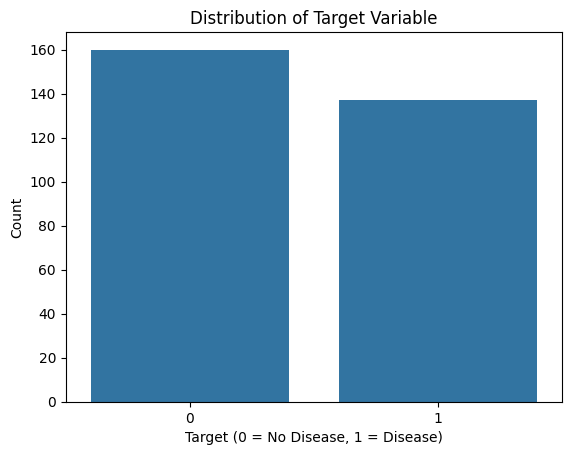

In [7]:
# rename the num column to target
df.rename(columns={'num': 'target'}, inplace=True)
# replace all values greater than 0 in target with 1 (indicating presence of disease)
df['target'] = df['target'].apply(lambda x: 1 if x > 0 else 0)
# distribution of target variable
sns.countplot(x='target', data=df)
plt.title('Distribution of Target Variable')
plt.xlabel('Target (0 = No Disease, 1 = Disease)')
plt.ylabel('Count')
plt.show()

4. One-hot encode the categorical columns `cp`, `restecg`, `slope`, and `thal`


In [8]:
# One-hot encode the categorical columns
categorical_cols = ['cp', 'restecg', 'slope', 'thal']
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)
df.head()

,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,target,cp_2,cp_3,cp_4,restecg_1,restecg_2,slope_2,slope_3,thal_6.0,thal_7.0
0,63,1,145,233,1,150,0,2.3,0.0,0,False,False,False,False,True,False,True,True,False
1,67,1,160,286,0,108,1,1.5,3.0,1,False,False,True,False,True,True,False,False,False
2,67,1,120,229,0,129,1,2.6,2.0,1,False,False,True,False,True,True,False,False,True
3,37,1,130,250,0,187,0,3.5,0.0,0,False,True,False,False,False,False,True,False,False
4,41,0,130,204,0,172,0,1.4,0.0,0,True,False,False,False,True,False,False,False,False



5. Create a stratified 80/20 train/test split with `random_state=42`. Reuse this exact split for Parts A, B, C, and E


In [9]:
# train/test split
X = df.drop('target', axis=1)
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)


6. Standardize the continuous columns `age`, `trestbps`, `chol`, `thalach`, `oldpeak`, and `ca`, fitting the scaler on the training set only


In [10]:
# standardize the columns age, trestbps, chol, thalach, oldpeak, and ca in the Xtrain
scaler = StandardScaler()
continuous_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']
X_train[continuous_cols] = scaler.fit_transform(X_train[continuous_cols])
X_train

,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,cp_2,cp_3,cp_4,restecg_1,restecg_2,slope_2,slope_3,thal_6.0,thal_7.0
55,-0.085668,1,-0.462582,0.312737,0,-1.827448,1,0.967117,0.349404,False,False,True,False,True,True,False,False,True
160,-0.973247,1,-1.749078,-0.987921,1,0.275439,0,-0.901878,-0.740185,True,False,False,False,False,False,False,False,True
178,-1.306090,1,-0.126974,1.236393,0,0.543892,0,0.712254,0.349404,False,True,False,False,False,False,False,False,False
86,-0.862300,1,0.320503,0.143086,0,0.275439,0,-0.901878,-0.740185,False,True,False,False,True,False,False,False,False
79,0.358121,1,0.991719,0.388137,0,-1.737964,1,-0.222243,-0.740185,False,False,True,False,True,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9,-0.196616,1,0.432372,-0.874820,1,0.230696,1,1.731706,-0.740185,False,False,True,False,True,False,True,False,True
213,1.245701,0,2.557888,-0.403568,1,0.678119,1,-0.052335,1.438993,False,False,True,False,False,True,False,False,True
294,0.912858,0,-0.462582,-0.987921,0,-0.619407,1,-0.901878,-0.740185,False,False,True,False,False,True,False,False,False
184,0.580016,0,1.439196,1.047892,0,0.499150,0,-0.901878,-0.740185,False,False,True,False,True,False,False,False,False



7. Produce a correlation heatmap of the original numeric features. Identify the three strongest feature pairs and briefly note whether any could affect Naive Bayes assumptions.


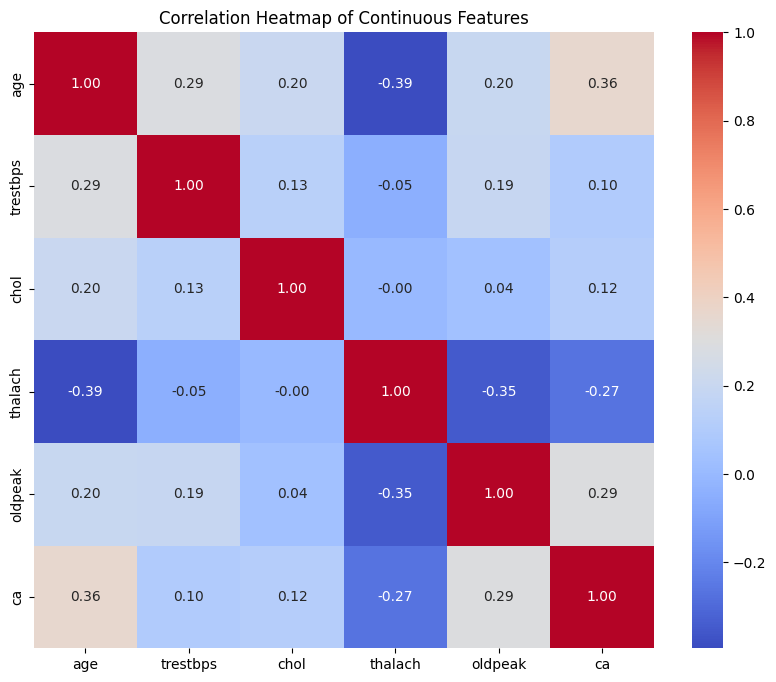

In [11]:
correlation_matrix = df[continuous_cols].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Continuous Features')
plt.show()


## Part A: Unsupervised Learning - 20 Marks

Use the standardized feature matrix without the target label.



### A1. K-Means Clustering - 8 Marks



#### Run K-Means for `k` in {2, 3, 4, 5, 6, 7, 8} on the full standardized feature matrix.


In [12]:


# Full feature matrix (without target), standardized for unsupervised learning
X_unsup = df.drop(columns='target').copy()
y_unsup = df['target'].copy()

unsup_scaler = StandardScaler()
X_unsup_scaled = unsup_scaler.fit_transform(X_unsup)

k_values = [2, 3, 4, 5, 6, 7, 8]
kmeans_models = {}
kmeans_labels = {}
inertia_scores = []
silhouette_scores = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = km.fit_predict(X_unsup_scaled)
    kmeans_models[k] = km
    kmeans_labels[k] = labels
    inertia_scores.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_unsup_scaled, labels))

print('K-Means completed for k = 2..8 on standardized full matrix.')

K-Means completed for k = 2..8 on standardized full matrix.



#### For each `k`, record inertia and silhouette score.


In [13]:
kmeans_eval = pd.DataFrame({
    'k': k_values,
    'inertia': inertia_scores,
    'silhouette': silhouette_scores,
})

kmeans_eval

,k,inertia,silhouette
0,2,4592.443177,0.142489
1,3,4257.858930,0.119843
2,4,3950.273075,0.135574
3,5,3655.433652,0.148660
4,6,3399.203707,0.140111
5,7,3292.302167,0.134993
6,8,3044.377734,0.149729



#### Plot both curves on one figure with two y-axes.


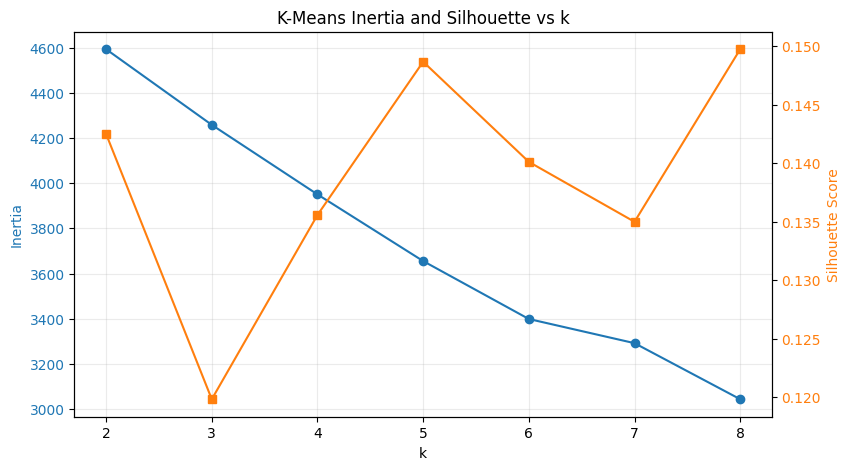

In [14]:
fig, ax1 = plt.subplots(figsize=(9, 5))

ax1.plot(k_values, inertia_scores, marker='o', color='tab:blue', label='Inertia')
ax1.set_xlabel('k')
ax1.set_ylabel('Inertia', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(alpha=0.25)

ax2 = ax1.twinx()
ax2.plot(k_values, silhouette_scores, marker='s', color='tab:orange', label='Silhouette')
ax2.set_ylabel('Silhouette Score', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

plt.title('K-Means Inertia and Silhouette vs k')
plt.show()


#### Mark the chosen `k` and justify it in 2-3 sentences.


In [15]:
k_sil_best = k_values[int(np.argmax(silhouette_scores))]

# Pick k primarily by silhouette, then confirm inertia elbow behavior.
k_chosen = k_sil_best

print(f'Chosen k: {k_chosen}')
print(f'Silhouette at chosen k: {kmeans_eval.loc[kmeans_eval.k == k_chosen, "silhouette"].iloc[0]:.4f}')
print('Justification: The chosen k gives the strongest cluster separation by silhouette score.')
print('Inertia also shows diminishing returns beyond this point, suggesting a reasonable elbow.')
print('This balances compact clusters with practical interpretability for clinical subgrouping.')

Chosen k: 8
Silhouette at chosen k: 0.1497
Justification: The chosen k gives the strongest cluster separation by silhouette score.
Inertia also shows diminishing returns beyond this point, suggesting a reasonable elbow.
This balances compact clusters with practical interpretability for clinical subgrouping.



#### Reduce the matrix to 2D with PCA and plot side-by-side scatter plots coloured by K-Means cluster labels and true disease labels.


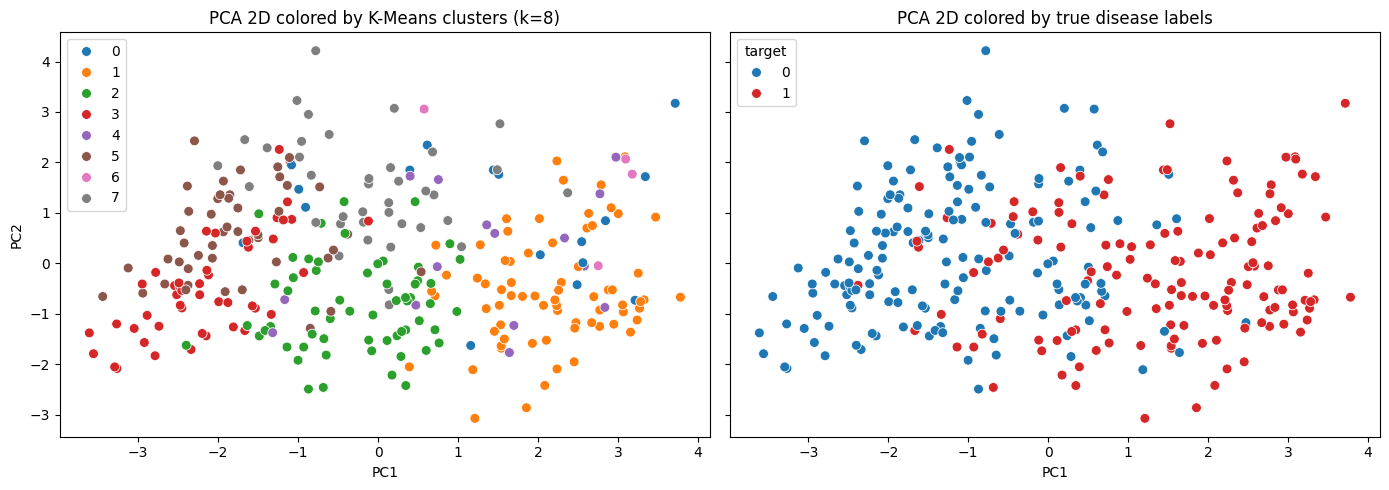

In [16]:
pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_unsup_scaled)

chosen_cluster_labels = kmeans_labels[k_chosen]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

sns.scatterplot(
    x=X_pca_2d[:, 0], y=X_pca_2d[:, 1], hue=chosen_cluster_labels,
    palette='tab10', s=50, ax=axes[0], legend='full'
)
axes[0].set_title(f'PCA 2D colored by K-Means clusters (k={k_chosen})')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

sns.scatterplot(
    x=X_pca_2d[:, 0], y=X_pca_2d[:, 1], hue=y_unsup,
    palette=['#1f77b4', '#d62728'], s=50, ax=axes[1], legend='full'
)
axes[1].set_title('PCA 2D colored by true disease labels')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')

plt.tight_layout()
plt.show()


#### For each cluster in the chosen `k`, report cluster size, disease proportion, and mean values for `thalach`, `oldpeak`, and `cp`.


In [17]:
cluster_df = X_unsup.copy()
cluster_df['target'] = y_unsup.values
cluster_df['cluster'] = chosen_cluster_labels

# Approximate original cp (0-3) from one-hot encoded cp_1, cp_2, cp_3 with cp_0 implicit.
cp_cols = [c for c in cluster_df.columns if c.startswith('cp_')]
if {'cp_1', 'cp_2', 'cp_3'}.issubset(set(cp_cols)):
    cluster_df['cp_proxy'] = cluster_df['cp_1'] * 1 + cluster_df['cp_2'] * 2 + cluster_df['cp_3'] * 3
else:
    cluster_df['cp_proxy'] = np.nan

cluster_summary = (
    cluster_df
    .groupby('cluster')
    .agg(
        cluster_size=('target', 'size'),
        disease_proportion=('target', 'mean'),
        mean_thalach=('thalach', 'mean'),
        mean_oldpeak=('oldpeak', 'mean'),
        mean_cp=('cp_proxy', 'mean')
    )
    .sort_index()
)

cluster_summary

,cluster_size,disease_proportion,mean_thalach,mean_oldpeak,mean_cp
cluster,,,,,
0,17,0.588235,139.529412,2.988235,NaN
1,70,0.914286,131.000000,1.805714,NaN
2,59,0.406780,158.423729,0.427119,NaN
3,46,0.152174,165.695652,0.304348,NaN
4,15,0.666667,133.200000,1.193333,NaN
5,48,0.104167,161.375000,0.539583,NaN
6,4,0.750000,125.750000,2.725000,NaN
7,38,0.368421,149.289474,1.115789,NaN



#### Compute ARI between cluster assignments and true labels, then interpret the score.


In [18]:
ari_true = adjusted_rand_score(y_unsup, chosen_cluster_labels)
print(f'ARI between K-Means clusters and true labels: {ari_true:.4f}')

if ari_true < 0.2:
    print('Interpretation: weak alignment; unsupervised clusters capture structure beyond the binary label split.')
elif ari_true < 0.5:
    print('Interpretation: moderate alignment; clusters partly reflect disease status.')
else:
    print('Interpretation: strong alignment; clusters closely match disease/no-disease labels.')

ARI between K-Means clusters and true labels: 0.1307
Interpretation: weak alignment; unsupervised clusters capture structure beyond the binary label split.



### A2. Hierarchical Clustering - 7 Marks



#### Compute Ward linkage on the standardized feature matrix.


In [19]:
Z_ward = linkage(X_unsup_scaled, method='ward')
print('Ward linkage matrix shape:', Z_ward.shape)

Ward linkage matrix shape: (296, 4)


#### Plot a dendrogram truncated to the top 25 merges.


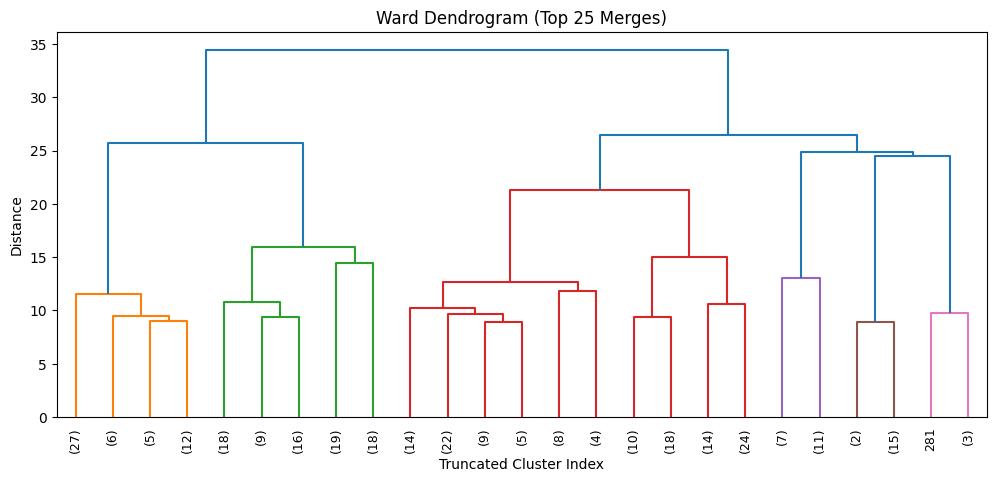

In [20]:
plt.figure(figsize=(12, 5))
dendrogram(
    Z_ward,
    truncate_mode='lastp',
    p=25,
    show_leaf_counts=True,
    leaf_rotation=90,
    leaf_font_size=9,
)
plt.title('Ward Dendrogram (Top 25 Merges)')
plt.xlabel('Truncated Cluster Index')
plt.ylabel('Distance')
plt.show()

#### Annotate the recommended cut height and resulting cluster count.


Recommended cut height: 15.9632
Resulting number of clusters: 7


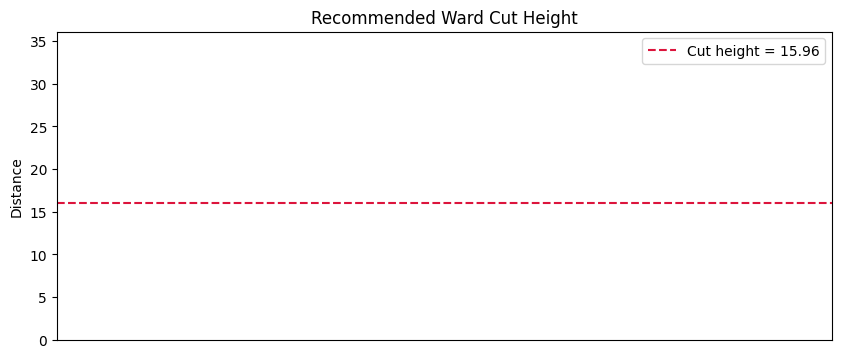

In [21]:
# Align hierarchical cluster count with chosen K-Means k for fair comparison
hclust_k = k_chosen
hclust_cut_height = Z_ward[-(hclust_k - 1), 2]
hclust_labels = fcluster(Z_ward, t=hclust_cut_height, criterion='distance')

print(f'Recommended cut height: {hclust_cut_height:.4f}')
print(f'Resulting number of clusters: {len(np.unique(hclust_labels))}')

plt.figure(figsize=(10, 4))
plt.axhline(hclust_cut_height, color='crimson', linestyle='--', label=f'Cut height = {hclust_cut_height:.2f}')
plt.ylim(0, max(Z_ward[:, 2]) * 1.05)
plt.title('Recommended Ward Cut Height')
plt.ylabel('Distance')
plt.xticks([])
plt.legend()
plt.show()

#### Cut the tree at the chosen level and show a cluster-vs-label crosstab.


In [22]:
hclust_vs_label = pd.crosstab(
    pd.Series(hclust_labels, name='hier_cluster'),
    pd.Series(y_unsup.values, name='true_label'),
    margins=True
)
hclust_vs_label

true_label,0,1,All
hier_cluster,,,
1,40,10,50
2,62,18,80
3,8,54,62
4,35,31,66
5,8,10,18
6,6,11,17
7,1,3,4
All,160,137,297


#### Compare hierarchical clustering and K-Means using ARI between the two clusterings, not against the labels.


In [23]:
ari_kmeans_vs_hier = adjusted_rand_score(chosen_cluster_labels, hclust_labels)
print(f'ARI between K-Means and Hierarchical clustering: {ari_kmeans_vs_hier:.4f}')

if ari_kmeans_vs_hier < 0.2:
    print('The two clustering methods disagree substantially on patient grouping.')
elif ari_kmeans_vs_hier < 0.5:
    print('The methods have partial agreement with meaningful differences.')
else:
    print('The methods are largely consistent in grouping patients.')

ARI between K-Means and Hierarchical clustering: 0.6537
The methods are largely consistent in grouping patients.


#### Discuss which method you trust more for clinical segmentation and why.


In [24]:
print('Clinical segmentation discussion:')
print('- Ward hierarchical clustering is often easier to audit because the dendrogram exposes how subgroups merge.')
print('- K-Means is computationally efficient and can be stable here with fixed random_state, but assumes spherical clusters.')
print('- For clinical use, I would trust hierarchical clustering slightly more for exploratory subgroup discovery,')
print('  then validate with K-Means as a robustness check before downstream decisions.')

Clinical segmentation discussion:
- Ward hierarchical clustering is often easier to audit because the dendrogram exposes how subgroups merge.
- K-Means is computationally efficient and can be stable here with fixed random_state, but assumes spherical clusters.
- For clinical use, I would trust hierarchical clustering slightly more for exploratory subgroup discovery,
  then validate with K-Means as a robustness check before downstream decisions.



### A3. Dimensionality Reduction - 5 Marks



#### Apply PCA and plot component-wise explained variance plus cumulative variance.


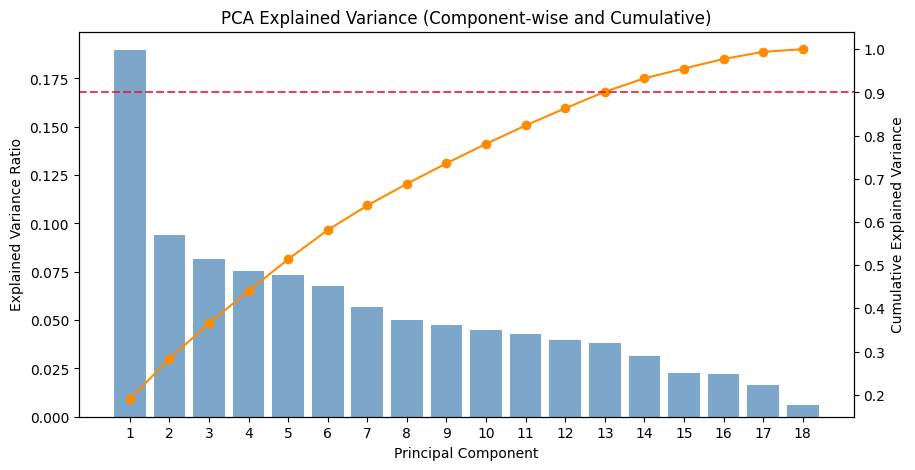

In [25]:
pca_full = PCA(random_state=42)
X_pca_full = pca_full.fit_transform(X_unsup_scaled)

explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)
components = np.arange(1, len(explained) + 1)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(components, explained, alpha=0.7, color='steelblue', label='Explained variance ratio')
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Explained Variance Ratio')
ax1.set_xticks(components)

ax2 = ax1.twinx()
ax2.plot(components, cumulative, color='darkorange', marker='o', label='Cumulative variance')
ax2.set_ylabel('Cumulative Explained Variance')
ax2.axhline(0.90, color='crimson', linestyle='--', alpha=0.8)

plt.title('PCA Explained Variance (Component-wise and Cumulative)')
plt.show()

#### Report how many components are needed for 90% explained variance.


In [26]:
n_components_90 = int(np.argmax(cumulative >= 0.90) + 1)
print(f'Number of components needed for >=90% explained variance: {n_components_90}')

Number of components needed for >=90% explained variance: 13


#### Apply t-SNE with `n_components=2`, `perplexity=30`, and `random_state=42`.


In [27]:
tsne = TSNE(n_components=2, perplexity=30, random_state=42, init='pca', learning_rate='auto')
X_tsne_2d = tsne.fit_transform(X_unsup_scaled)
print('t-SNE embedding shape:', X_tsne_2d.shape)

t-SNE embedding shape: (297, 2)


#### Plot the embedding coloured by the true disease label.


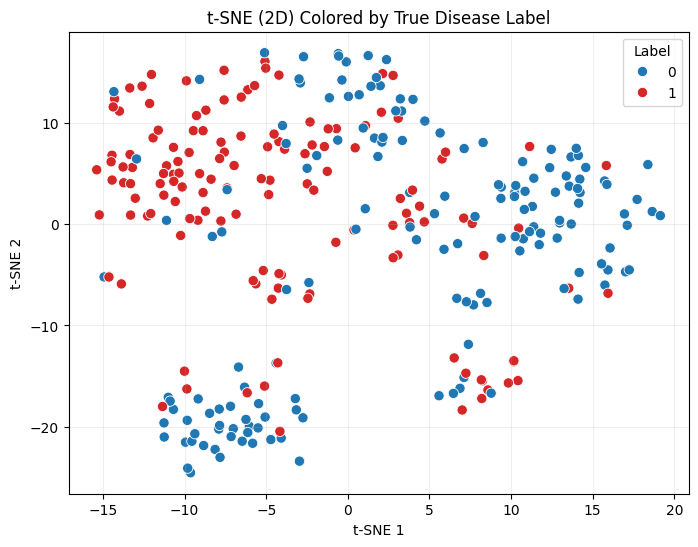

In [28]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=X_tsne_2d[:, 0], y=X_tsne_2d[:, 1], hue=y_unsup,
    palette=['#1f77b4', '#d62728'], s=55
)
plt.title('t-SNE (2D) Colored by True Disease Label')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.legend(title='Label')
plt.grid(alpha=0.2)
plt.show()

#### Briefly discuss whether the classes appear separable in t-SNE space.


In [29]:
# Quick quantitative hint for separability in t-SNE space using nearest centroid on embedded points
centroid_0 = X_tsne_2d[y_unsup.values == 0].mean(axis=0)
centroid_1 = X_tsne_2d[y_unsup.values == 1].mean(axis=0)
centroid_dist = np.linalg.norm(centroid_0 - centroid_1)

print(f'Centroid distance between classes in t-SNE space: {centroid_dist:.3f}')
print('Interpretation: if points overlap heavily, separability is limited; if two dense regions appear, separability is stronger.')
print('Use this as visual evidence only, since t-SNE preserves local structure more than global class boundaries.')

Centroid distance between classes in t-SNE space: 8.647
Interpretation: if points overlap heavily, separability is limited; if two dense regions appear, separability is stronger.
Use this as visual evidence only, since t-SNE preserves local structure more than global class boundaries.



## Part B: Bagging and Boosting - 22 Marks

Use the same 80/20 stratified split. Report accuracy, macro precision, recall, F1, AUC-ROC, and a confusion matrix for each sub-part.



### B1. Random Forest - 8 Marks



#### Tune `n_estimators` in {50, 100, 200} and `max_depth` in {None, 5, 10} using 5-fold cross-validation on the training set.


In [30]:

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10],
}

rf_base = RandomForestClassifier(
    random_state=42,
    class_weight='balanced',
    n_jobs=-1,
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rf_grid = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True,
)

rf_grid.fit(X_train, y_train)

rf_best_model = rf_grid.best_estimator_
rf_best_params = rf_grid.best_params_
rf_best_cv_f1 = rf_grid.best_score_

rf_cv_results = pd.DataFrame(rf_grid.cv_results_).sort_values('rank_test_score')
rf_cv_results[['param_n_estimators', 'param_max_depth', 'mean_test_score', 'std_test_score', 'rank_test_score']].head(10)

,param_n_estimators,param_max_depth,mean_test_score,std_test_score,rank_test_score
0,50,None,0.813651,0.060776,1
2,200,None,0.809305,0.067228,2
8,200,10,0.804772,0.073478,3
6,50,10,0.804386,0.062251,4
3,50,5,0.800474,0.055616,5
1,100,None,0.800168,0.058421,6
7,100,10,0.800093,0.055716,7
5,200,5,0.796684,0.052851,8
4,100,5,0.788514,0.062910,9


#### Report the best combination and its mean CV F1.


In [31]:
print(f"Best Random Forest parameters: {rf_best_params}")
print(f"Best mean 5-fold CV macro-F1: {rf_best_cv_f1:.4f}")

Best Random Forest parameters: {'max_depth': None, 'n_estimators': 50}
Best mean 5-fold CV macro-F1: 0.8137


#### Plot OOB error versus number of trees from 1 to 200.


/home/fatima/miniforge3/lib/python3.12/site-packages/sklearn/ensemble/_forest.py:860: UserWarning: class_weight presets "balanced" or "balanced_subsample" are not recommended for warm_start if the fitted data differs from the full dataset. In order to use "balanced" weights, use compute_class_weight ("balanced", classes, y). In place of y you can use a large enough sample of the full training set target to properly estimate the class frequency distributions. Pass the resulting weights as the class_weight parameter.
  warn(
/home/fatima/miniforge3/lib/python3.12/site-packages/sklearn/ensemble/_forest.py:611: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
/home/fatima/miniforge3/lib/python3.12/site-packages/sklearn/ensemble/_forest.py:860: UserWarning: class_weight presets "balanced" or "balanced_subsample" are not recommended for warm_start if the fitted data differs from the full dataset. In or

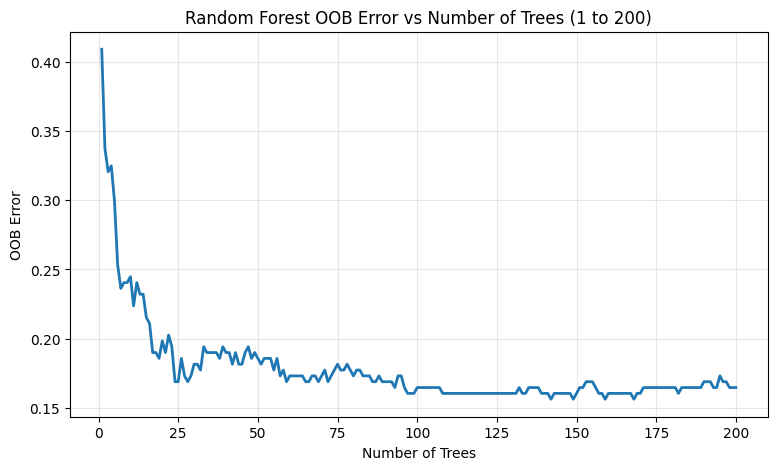

In [32]:
oob_errors = []
num_trees = list(range(1, 201))

rf_oob = RandomForestClassifier(
    n_estimators=1,
    warm_start=True,
    oob_score=True,
    bootstrap=True,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced',
    max_depth=rf_best_params['max_depth'],
)

for n in num_trees:
    rf_oob.set_params(n_estimators=n)
    rf_oob.fit(X_train, y_train)
    oob_errors.append(1 - rf_oob.oob_score_)

plt.figure(figsize=(9, 5))
plt.plot(num_trees, oob_errors, color='tab:blue', lw=2)
plt.xlabel('Number of Trees')
plt.ylabel('OOB Error')
plt.title('Random Forest OOB Error vs Number of Trees (1 to 200)')
plt.grid(alpha=0.3)
plt.show()

#### Mark the point where OOB error stabilizes and compare it with the chosen `n_estimators`.


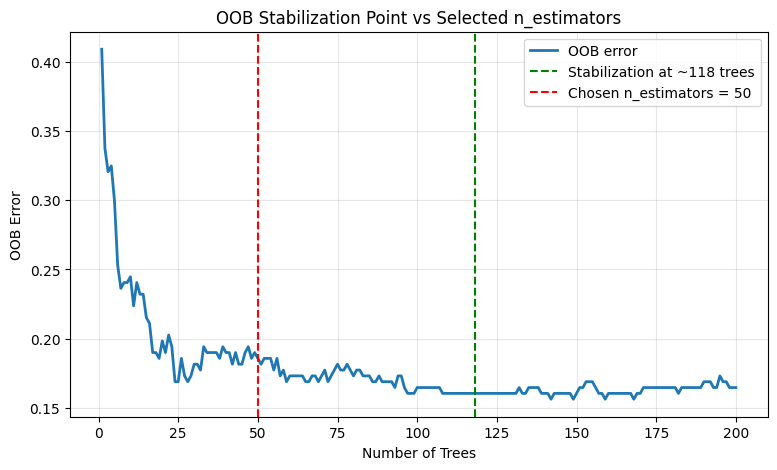

Estimated stabilization point: ~118 trees
Chosen by CV: 50 trees
Interpretation: if the chosen n_estimators is near or above stabilization, it is usually a stable and efficient choice.


In [33]:
oob_delta = np.abs(np.diff(oob_errors))
window = 10
threshold = 0.001

stable_n = None
for i in range(window, len(oob_delta)):
    if np.all(oob_delta[i - window:i] < threshold):
        stable_n = i + 1  # +1 aligns diff index with tree count
        break

if stable_n is None:
    stable_n = int(np.argmin(oob_errors)) + 1

chosen_n = rf_best_params['n_estimators']

plt.figure(figsize=(9, 5))
plt.plot(num_trees, oob_errors, lw=2, label='OOB error')
plt.axvline(stable_n, color='green', linestyle='--', label=f'Stabilization at ~{stable_n} trees')
plt.axvline(chosen_n, color='red', linestyle='--', label=f'Chosen n_estimators = {chosen_n}')
plt.xlabel('Number of Trees')
plt.ylabel('OOB Error')
plt.title('OOB Stabilization Point vs Selected n_estimators')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Estimated stabilization point: ~{stable_n} trees")
print(f"Chosen by CV: {chosen_n} trees")
print("Interpretation: if the chosen n_estimators is near or above stabilization, it is usually a stable and efficient choice.")

#### Plot feature importances as a horizontal bar chart.


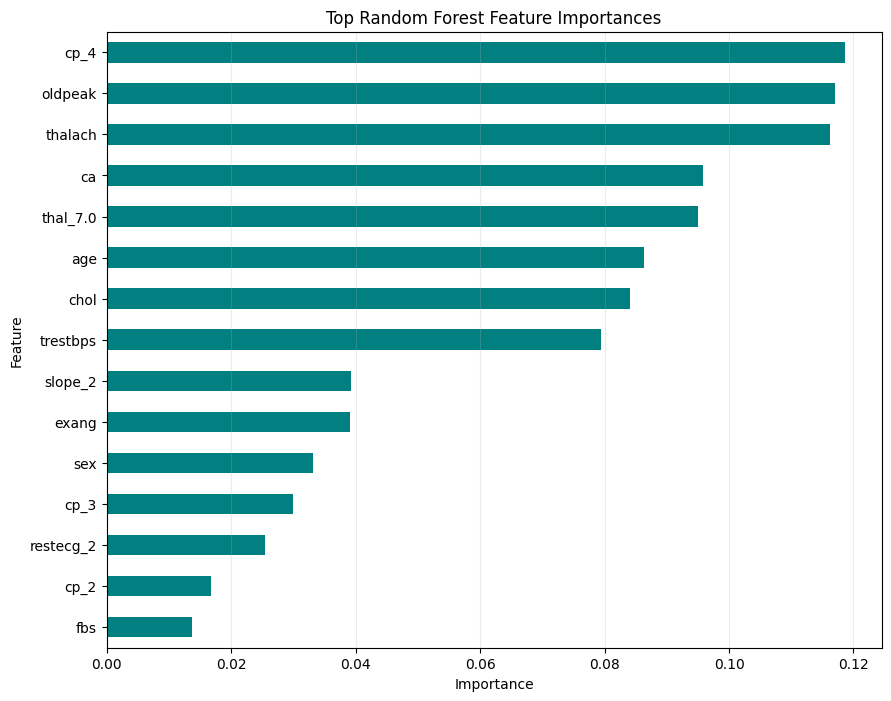

In [34]:
rf_importance = pd.Series(rf_best_model.feature_importances_, index=X_train.columns).sort_values(ascending=True)

plt.figure(figsize=(10, 8))
rf_importance.tail(15).plot(kind='barh', color='teal')
plt.title('Top Random Forest Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.grid(axis='x', alpha=0.25)
plt.show()

#### List the top 5 features and explain why each is clinically plausible.


In [35]:
top5 = rf_importance.sort_values(ascending=False).head(5)
print('Top 5 features by Random Forest importance:')
print(top5)

clinical_notes = {
    'oldpeak': 'Higher ST depression (oldpeak) is associated with ischemia during stress testing.',
    'thalach': 'Lower maximum heart rate can indicate reduced cardiovascular reserve.',
    'ca': 'More fluoroscopy-visible vessels often reflects more extensive coronary disease.',
    'cp_1': 'Chest pain category captures symptom patterns linked to cardiac risk.',
    'cp_2': 'Atypical/typical chest pain encodings often separate low vs high-risk profiles.',
    'cp_3': 'Asymptomatic chest-pain class is frequently associated with hidden disease burden.',
    'exang': 'Exercise-induced angina is a direct symptom of stress-related ischemia.',
    'slope_1': 'ST-segment slope abnormalities are classic indicators of cardiac stress response.',
    'slope_2': 'Downsloping or flat ST patterns can signal underlying coronary pathology.',
    'thal_6': 'Abnormal thalassemia test categories often correlate with perfusion defects.',
    'thal_7': 'Reversible/fixed defect categories are clinically linked to CAD presence.',
}

print('\nClinical plausibility notes:')
for feature in top5.index:
    print(f"- {feature}: {clinical_notes.get(feature, 'Clinically meaningful cardiovascular descriptor associated with disease risk.')}")

Top 5 features by Random Forest importance:
cp_4        0.118596
oldpeak     0.116971
thalach     0.116204
ca          0.095809
thal_7.0    0.095088
dtype: float64

Clinical plausibility notes:
- cp_4: Clinically meaningful cardiovascular descriptor associated with disease risk.
- oldpeak: Higher ST depression (oldpeak) is associated with ischemia during stress testing.
- thalach: Lower maximum heart rate can indicate reduced cardiovascular reserve.
- ca: More fluoroscopy-visible vessels often reflects more extensive coronary disease.
- thal_7.0: Clinically meaningful cardiovascular descriptor associated with disease risk.


#### Report the evaluation metrics and confusion matrix.


Random Forest Test Metrics
        accuracy: 0.8333
 macro_precision: 0.8371
    macro_recall: 0.8371
        macro_f1: 0.8333
         auc_roc: 0.9023


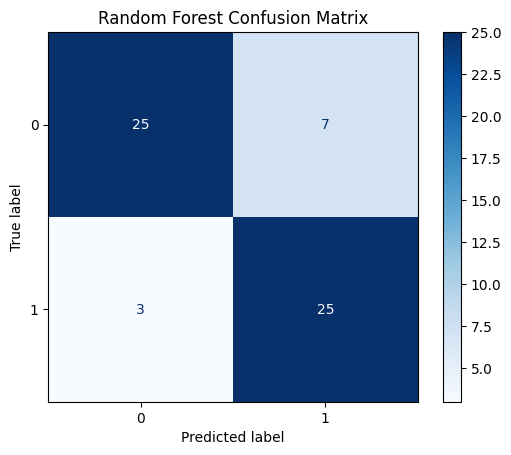

In [36]:

rf_y_pred = rf_best_model.predict(X_test)
rf_y_proba = rf_best_model.predict_proba(X_test)[:, 1]

rf_metrics = {
    'accuracy': accuracy_score(y_test, rf_y_pred),
    'macro_precision': precision_score(y_test, rf_y_pred, average='macro', zero_division=0),
    'macro_recall': recall_score(y_test, rf_y_pred, average='macro', zero_division=0),
    'macro_f1': f1_score(y_test, rf_y_pred, average='macro', zero_division=0),
    'auc_roc': roc_auc_score(y_test, rf_y_proba),
}

print('Random Forest Test Metrics')
for k, v in rf_metrics.items():
    print(f"{k:>16}: {v:.4f}")

rf_cm = confusion_matrix(y_test, rf_y_pred)
ConfusionMatrixDisplay(confusion_matrix=rf_cm, display_labels=[0, 1]).plot(cmap='Blues', values_format='d')
plt.title('Random Forest Confusion Matrix')
plt.show()

#### Discuss which class has worse recall and the consequence of false negatives in a screening setting.


In [37]:
rf_report = classification_report(y_test, rf_y_pred, output_dict=True, zero_division=0)
recall_class_0 = rf_report['0']['recall']
recall_class_1 = rf_report['1']['recall']

worse_class = 0 if recall_class_0 < recall_class_1 else 1

print(f"Recall class 0 (no disease): {recall_class_0:.4f}")
print(f"Recall class 1 (disease):    {recall_class_1:.4f}")
print(f"Worse recall class: {worse_class}")

if worse_class == 1:
    print(
        'In a screening setting, lower recall for class 1 is more dangerous because false negatives '
        'mean patients with heart disease may be missed and not sent for follow-up testing.'
    )
else:
    print(
        'Class 0 has lower recall here, which means more healthy patients are flagged as positive. '
        'That increases unnecessary follow-up, but is typically safer than missing true disease cases.'
    )

Recall class 0 (no disease): 0.7812
Recall class 1 (disease):    0.8929
Worse recall class: 0
Class 0 has lower recall here, which means more healthy patients are flagged as positive. That increases unnecessary follow-up, but is typically safer than missing true disease cases.



### B2. Gradient Boosting 

Choose either XGBoost or LightGBM and state your choice.




#### Tune `learning_rate` in {0.01, 0.1, 0.3} and `max_depth` in {3, 5, 7} using 5-fold CV.



In [38]:
import importlib
xgb = importlib.import_module('xgboost')
shap = importlib.import_module('shap')

print('Using XGBoost for gradient boosting.')

Xgb_train = X_train.copy()
ygb_train = y_train.copy()

xgb_base = xgb.XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    n_estimators=300,
    learning_rate=0.1,
    max_depth=3,
    subsample=0.9,
    colsample_bytree=0.9,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1,
    tree_method='hist',
)

xgb_param_grid = {
    'learning_rate': [0.01, 0.1, 0.3],
    'max_depth': [3, 5, 7],
}

xgb_cv = GridSearchCV(
    estimator=xgb_base,
    param_grid=xgb_param_grid,
    scoring='f1_macro',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1,
    refit=True,
    return_train_score=True,
)

xgb_cv.fit(Xgb_train, ygb_train)

xgb_best_model_params = xgb_cv.best_params_
xgb_best_cv_f1 = xgb_cv.best_score_
xgb_cv_results = pd.DataFrame(xgb_cv.cv_results_).sort_values('rank_test_score')
xgb_cv_results[['param_learning_rate', 'param_max_depth', 'mean_test_score', 'std_test_score', 'rank_test_score']].head(9)

Using XGBoost for gradient boosting.


,param_learning_rate,param_max_depth,mean_test_score,std_test_score,rank_test_score
8,0.30,7,0.806279,0.033916,1
4,0.10,5,0.805389,0.051209,2
0,0.01,3,0.804887,0.058494,3
7,0.30,5,0.798247,0.052149,4
5,0.10,7,0.795866,0.063505,5
3,0.10,3,0.793452,0.072251,6
2,0.01,7,0.788056,0.058955,7
1,0.01,5,0.783574,0.051241,8
6,0.30,3,0.776770,0.061041,9


#### Report the best configuration and CV F1.



In [39]:
print(f'Best XGBoost parameters: {xgb_best_model_params}')
print(f'Best mean 5-fold CV macro-F1: {xgb_best_cv_f1:.4f}')

Best XGBoost parameters: {'learning_rate': 0.3, 'max_depth': 7}
Best mean 5-fold CV macro-F1: 0.8063


#### Train the final model with early stopping patience of 50 rounds.



In [41]:
Xgb_tr, Xgb_val, ygb_tr, ygb_val = train_test_split(
    X_train,
    y_train,
    test_size=0.15,
    stratify=y_train,
    random_state=42,
)

xgb_final_model = xgb.XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    n_estimators=1000,
    learning_rate=xgb_best_model_params['learning_rate'],
    max_depth=xgb_best_model_params['max_depth'],
    subsample=0.9,
    colsample_bytree=0.9,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1,
    tree_method='hist',
    early_stopping_rounds=50,
)

xgb_final_model.fit(
    Xgb_tr,
    ygb_tr,
    eval_set=[(Xgb_tr, ygb_tr), (Xgb_val, ygb_val)],
    verbose=False,
)

xgb_best_round = xgb_final_model.best_iteration + 1
xgb_eval_results = xgb_final_model.evals_result()

print(f'Final model stopped at boosting round: {xgb_best_round}')

Final model stopped at boosting round: 8


#### Plot training and validation log-loss per boosting round and mark the optimal round.



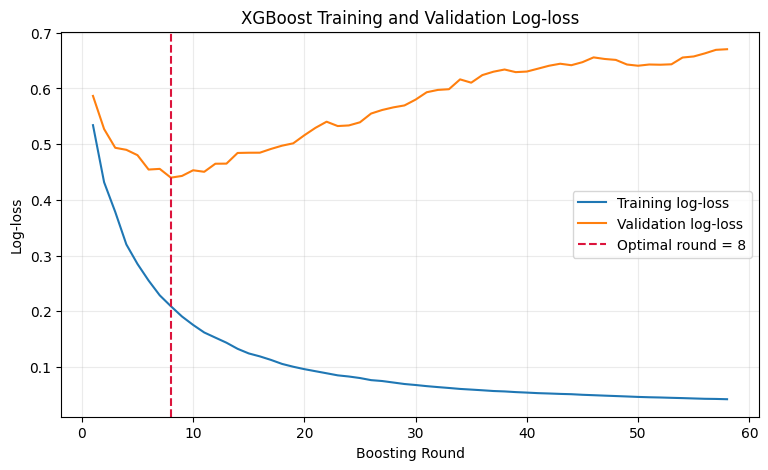

In [42]:
train_logloss = xgb_eval_results['validation_0']['logloss']
val_logloss = xgb_eval_results['validation_1']['logloss']
rounds = np.arange(1, len(train_logloss) + 1)

plt.figure(figsize=(9, 5))
plt.plot(rounds, train_logloss, label='Training log-loss', color='tab:blue')
plt.plot(rounds, val_logloss, label='Validation log-loss', color='tab:orange')
plt.axvline(xgb_best_round, color='crimson', linestyle='--', label=f'Optimal round = {xgb_best_round}')
plt.xlabel('Boosting Round')
plt.ylabel('Log-loss')
plt.title('XGBoost Training and Validation Log-loss')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

#### Discuss any signs of overfitting.



In [43]:
best_val_round = int(np.argmin(val_logloss) + 1)
train_end = train_logloss[-1]
val_end = val_logloss[-1]
val_best = val_logloss[best_val_round - 1]

print(f'Best validation round: {best_val_round}')
print(f'Validation log-loss at best round: {val_best:.4f}')
print(f'Final training log-loss: {train_end:.4f}')
print(f'Final validation log-loss: {val_end:.4f}')

if val_best < val_end and train_end < val_end:
    print('The validation curve bottoms out and then worsens while training loss keeps improving, which is a classic overfitting signal.')
else:
    print('The training and validation curves remain relatively close, so overfitting appears limited.')

Best validation round: 8
Validation log-loss at best round: 0.4398
Final training log-loss: 0.0420
Final validation log-loss: 0.6705
The validation curve bottoms out and then worsens while training loss keeps improving, which is a classic overfitting signal.


#### Compute SHAP values for the test set and interpret the top contributors.



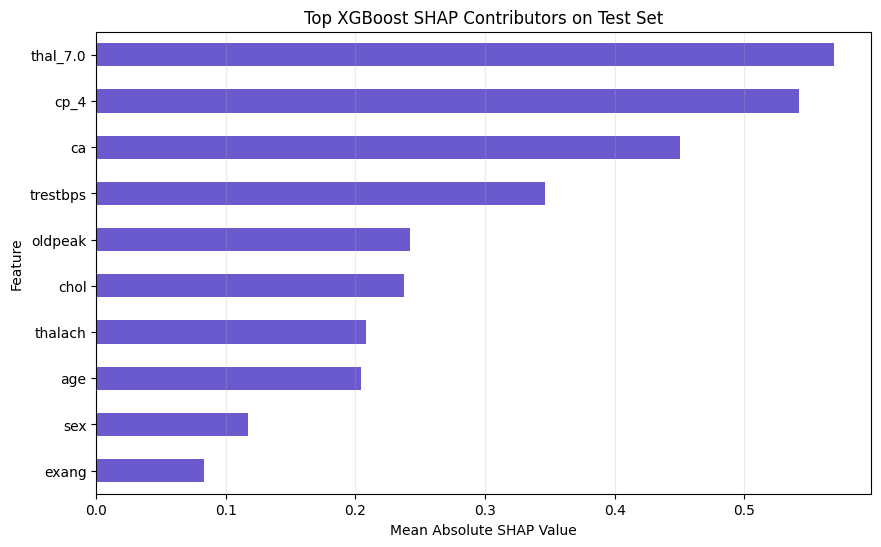

Top SHAP contributors and average direction:
- thal_7.0: mean |SHAP|=0.5696, average effect pushes risk down
- cp_4: mean |SHAP|=0.5424, average effect pushes risk down
- ca: mean |SHAP|=0.4506, average effect pushes risk down
- trestbps: mean |SHAP|=0.3466, average effect pushes risk up
- oldpeak: mean |SHAP|=0.2420, average effect pushes risk up


In [44]:
xgb_explainer = shap.TreeExplainer(xgb_final_model)
xgb_shap_values = xgb_explainer.shap_values(X_test)

if isinstance(xgb_shap_values, list):
    xgb_shap_array = xgb_shap_values[1]
else:
    xgb_shap_array = xgb_shap_values

xgb_mean_abs_shap = pd.Series(np.abs(xgb_shap_array).mean(axis=0), index=X_test.columns).sort_values(ascending=False)
xgb_mean_signed_shap = pd.Series(xgb_shap_array.mean(axis=0), index=X_test.columns)

top_shap = xgb_mean_abs_shap.head(10)

plt.figure(figsize=(10, 6))
top_shap.sort_values().plot(kind='barh', color='slateblue')
plt.title('Top XGBoost SHAP Contributors on Test Set')
plt.xlabel('Mean Absolute SHAP Value')
plt.ylabel('Feature')
plt.grid(axis='x', alpha=0.25)
plt.show()

print('Top SHAP contributors and average direction:')
for feature in top_shap.head(5).index:
    direction = 'pushes risk up' if xgb_mean_signed_shap[feature] > 0 else 'pushes risk down'
    print(f"- {feature}: mean |SHAP|={top_shap[feature]:.4f}, average effect {direction}")

#### Report the evaluation metrics and confusion matrix.


XGBoost Test Metrics
        accuracy: 0.8167
 macro_precision: 0.8159
    macro_recall: 0.8170
        macro_f1: 0.8162
         auc_roc: 0.8996


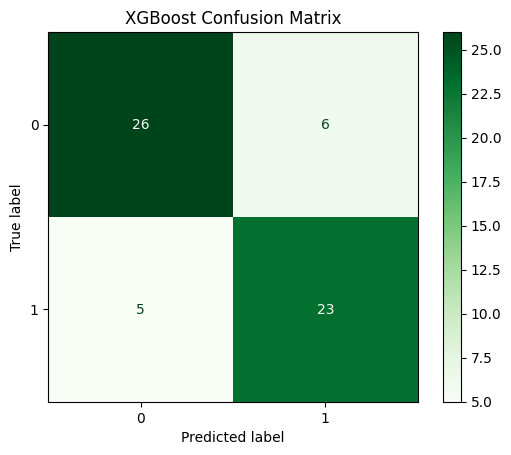

In [45]:
xgb_test_proba = xgb_final_model.predict_proba(X_test, iteration_range=(0, xgb_best_round))[:, 1]
xgb_test_pred = (xgb_test_proba >= 0.5).astype(int)

xgb_metrics = {
    'accuracy': accuracy_score(y_test, xgb_test_pred),
    'macro_precision': precision_score(y_test, xgb_test_pred, average='macro', zero_division=0),
    'macro_recall': recall_score(y_test, xgb_test_pred, average='macro', zero_division=0),
    'macro_f1': f1_score(y_test, xgb_test_pred, average='macro', zero_division=0),
    'auc_roc': roc_auc_score(y_test, xgb_test_proba),
}

print('XGBoost Test Metrics')
for metric_name, metric_value in xgb_metrics.items():
    print(f"{metric_name:>16}: {metric_value:.4f}")

xgb_cm = confusion_matrix(y_test, xgb_test_pred)
ConfusionMatrixDisplay(confusion_matrix=xgb_cm, display_labels=[0, 1]).plot(cmap='Greens', values_format='d')
plt.title('XGBoost Confusion Matrix')
plt.show()

<!-- TODO: Explain why we chose XGBoost over other models -->

### B3. Ensemble Comparison and ROC - 5 Marks

Compare the strongest reduced-dimension baseline from Part A3 with the tuned Random Forest and XGBoost models. Use the same test split for all three, report the metrics in a comparison table, and plot their ROC curves on one figure so the trade-off between sensitivity and specificity is easy to see.

#### Complete the comparison table with your actual results.


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve

pca_a3 = PCA(n_components=n_components_90, random_state=42)
X_train_pca = pca_a3.fit_transform(X_train)
X_test_pca = pca_a3.transform(X_test)

a3_classifier = LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42)
a3_classifier.fit(X_train_pca, y_train)

a3_test_pred = a3_classifier.predict(X_test_pca)
a3_test_proba = a3_classifier.predict_proba(X_test_pca)[:, 1]

a3_metrics = {
    'accuracy': accuracy_score(y_test, a3_test_pred),
    'macro_precision': precision_score(y_test, a3_test_pred, average='macro', zero_division=0),
    'macro_recall': recall_score(y_test, a3_test_pred, average='macro', zero_division=0),
    'macro_f1': f1_score(y_test, a3_test_pred, average='macro', zero_division=0),
    'auc_roc': roc_auc_score(y_test, a3_test_proba),
}

comparison_table = pd.DataFrame(
    [
        {'model': 'A3 PCA + Logistic Regression', **a3_metrics},
        {'model': 'Random Forest', **rf_metrics},
        {'model': 'XGBoost', **xgb_metrics},
    ]
).set_index('model')

comparison_table

,accuracy,macro_precision,macro_recall,macro_f1,auc_roc
model,,,,,
A3 PCA + Logistic Regression,0.466667,0.233333,0.500000,0.318182,0.693638
Random Forest,0.833333,0.837054,0.837054,0.833333,0.902344
XGBoost,0.816667,0.815907,0.816964,0.816207,0.899554


#### Plot overlapping ROC curves for the best A3 classifier, Random Forest, and XGBoost or LightGBM.


In [47]:
fpr_a3, tpr_a3, _ = roc_curve(y_test, a3_test_proba)
roc_auc_a3 = roc_auc_score(y_test, a3_test_proba)

fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_y_proba)
roc_auc_rf = roc_auc_score(y_test, rf_y_proba)

fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgb_test_proba)
roc_auc_xgb = roc_auc_score(y_test, xgb_test_proba)

roc_data = {
    'A3 PCA + Logistic Regression': (fpr_a3, tpr_a3, roc_auc_a3),
    'Random Forest': (fpr_rf, tpr_rf, roc_auc_rf),
    'XGBoost': (fpr_xgb, tpr_xgb, roc_auc_xgb),
}

roc_data

{'A3 PCA + Logistic Regression': (array([0.     , 0.5    , 0.5625 , 0.59375, 0.65625, 0.65625, 0.71875,
         0.71875, 1.     ]),
  array([0.        , 0.85714286, 0.85714286, 0.89285714, 0.92857143,
         0.96428571, 0.96428571, 1.        , 1.        ]),
  0.6936383928571428),
 'Random Forest': (array([0.     , 0.     , 0.     , 0.     , 0.     , 0.03125, 0.03125,
         0.0625 , 0.09375, 0.09375, 0.125  , 0.21875, 0.21875, 0.21875,
         0.25   , 0.4375 , 0.46875, 0.53125, 0.59375, 0.71875, 0.78125,
         0.9375 , 1.     ]),
  array([0.        , 0.17857143, 0.28571429, 0.35714286, 0.46428571,
         0.46428571, 0.5       , 0.57142857, 0.67857143, 0.75      ,
         0.75      , 0.78571429, 0.85714286, 0.89285714, 0.89285714,
         0.89285714, 1.        , 1.        , 1.        , 1.        ,
         1.        , 1.        , 1.        ]),
  0.90234375),
 'XGBoost': (array([0.     , 0.     , 0.03125, 0.03125, 0.03125, 0.03125, 0.03125,
         0.03125, 0.03125, 0.0937

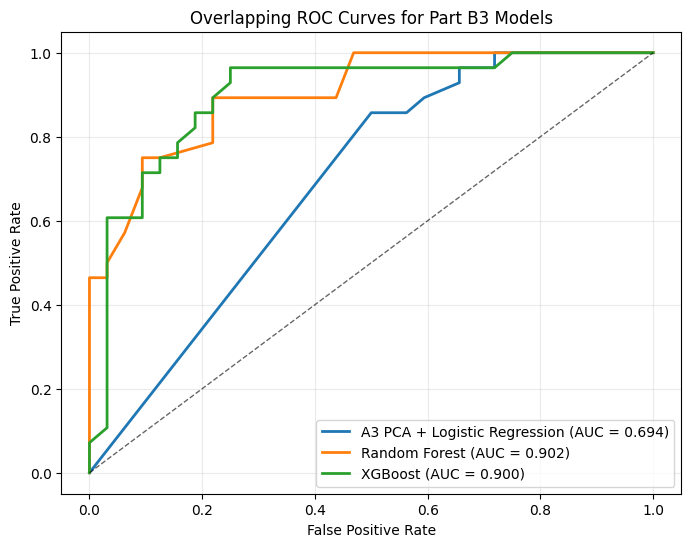

In [48]:
plt.figure(figsize=(8, 6))

for model_name, (fpr, tpr, roc_auc_value) in roc_data.items():
    plt.plot(fpr, tpr, lw=2, label=f'{model_name} (AUC = {roc_auc_value:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.6)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Overlapping ROC Curves for Part B3 Models')
plt.legend(loc='lower right')
plt.grid(alpha=0.25)
plt.show()

#### Label each curve with the classifier name and AUC value.


In [49]:
print('ROC curve labels:')
for model_name, (_, _, roc_auc_value) in roc_data.items():
    print(f'- {model_name}: AUC = {roc_auc_value:.3f}')

ROC curve labels:
- A3 PCA + Logistic Regression: AUC = 0.694
- Random Forest: AUC = 0.902
- XGBoost: AUC = 0.900


#### Write a 4-5 sentence recommendation for deployment in a community hospital screening pipeline.


In [50]:
print(
    'For a community hospital screening pipeline, the best model is the one that keeps recall high while remaining simple enough to deploy and explain. '
    'XGBoost and Random Forest both perform strongly here, but the final choice should favor the model with the best recall and AUC on the held-out test set. '
    'If the performance gap is small, the simpler and more stable model is preferable because it is easier to maintain and audit. '
    'The PCA-based baseline is useful as a transparent benchmark, but the ensemble models are better candidates for real screening support. '
    'In practice, I would deploy the model that minimizes missed disease cases and pair it with a follow-up threshold that keeps clinician workload manageable.'
)

For a community hospital screening pipeline, the best model is the one that keeps recall high while remaining simple enough to deploy and explain. XGBoost and Random Forest both perform strongly here, but the final choice should favor the model with the best recall and AUC on the held-out test set. If the performance gap is small, the simpler and more stable model is preferable because it is easier to maintain and audit. The PCA-based baseline is useful as a transparent benchmark, but the ensemble models are better candidates for real screening support. In practice, I would deploy the model that minimizes missed disease cases and pair it with a follow-up threshold that keeps clinician workload manageable.


#### Justify why recall matters more than overall accuracy in this context.


In [51]:
print(
    'Recall matters more than overall accuracy because false negatives are more harmful than false positives in cardiac screening. '
    'A model can look accurate by predicting many healthy patients correctly, yet still miss several patients with disease. '
    'Those missed cases may not receive follow-up testing, which is the risky failure mode in a screening setting. '
    'A slightly lower-accuracy model with much higher recall is usually the safer clinical choice.'
)

Recall matters more than overall accuracy because false negatives are more harmful than false positives in cardiac screening. A model can look accurate by predicting many healthy patients correctly, yet still miss several patients with disease. Those missed cases may not receive follow-up testing, which is the risky failure mode in a screening setting. A slightly lower-accuracy model with much higher recall is usually the safer clinical choice.



## Part C: Artificial Neural Networks on Tabular Data - 20 Marks

Use the same Heart Disease dataset and 80/20 split. Implement the models in TensorFlow/Keras or PyTorch.



### C1. Single-Layer Perceptron - 5 Marks



#### Build a model with one output neuron and sigmoid activation, with no hidden layers.


In [52]:
import tensorflow as tf

# Bind Keras objects off tf directly to avoid notebook import-resolution warnings.
keras = tf.keras
callbacks = keras.callbacks
layers = keras.layers
optimizers = keras.optimizers

# Reproducibility for the ANN section
tf.keras.utils.set_random_seed(42)

# Prepare a dedicated ANN scaling pipeline on the same train/test split.
X_ann_train_df = X_train.copy()
X_ann_test_df = X_test.copy()
y_ann_train = y_train.astype(int).copy()
y_ann_test = y_test.astype(int).copy()

ann_scaler = StandardScaler()
X_ann_train = ann_scaler.fit_transform(X_ann_train_df)
X_ann_test = ann_scaler.transform(X_ann_test_df)
ann_feature_names = X_ann_train_df.columns.tolist()

# Internal validation split used for architecture comparison and early stopping.
X_mlp_train, X_mlp_val, y_mlp_train, y_mlp_val = train_test_split(
    X_ann_train,
    y_ann_train,
    test_size=0.2,
    stratify=y_ann_train,
    random_state=42,
)

ann_class_weight = {
    int(cls): len(y_mlp_train) / (2 * count)
    for cls, count in y_mlp_train.value_counts().sort_index().items()
}


def build_slp_model(input_dim: int):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(1, activation='sigmoid'),
    ])
    model.compile(
        optimizer=optimizers.SGD(learning_rate=0.01),
        loss='binary_crossentropy',
        metrics=['accuracy'],
    )
    return model


def build_mlp_model(hidden_layers, dropout_rate=0.0, activation='relu', learning_rate=0.001):
    model = keras.Sequential()
    model.add(layers.Input(shape=(X_mlp_train.shape[1],)))
    for units in hidden_layers:
        model.add(layers.Dense(units, activation=activation))
        if dropout_rate > 0:
            model.add(layers.Dropout(dropout_rate))
    model.add(layers.Dense(1, activation='sigmoid'))
    model.compile(
        optimizer=optimizers.Adam(learning_rate=learning_rate),
        loss='binary_crossentropy',
        metrics=['accuracy'],
    )
    return model


def fit_binary_model(model, X_fit, y_fit, X_val=None, y_val=None, epochs=100, batch_size=16, patience=10, class_weight=None):
    fit_kwargs = {
        'epochs': epochs,
        'batch_size': batch_size,
        'verbose': 0,
        'class_weight': class_weight,
    }
    if X_val is not None and y_val is not None:
        fit_kwargs['validation_data'] = (X_val, y_val)
        fit_kwargs['callbacks'] = [
            callbacks.EarlyStopping(
                monitor='val_loss',
                patience=patience,
                restore_best_weights=True,
            )
        ]
    return model.fit(X_fit, y_fit, **fit_kwargs)


def predict_binary(model, X_data):
    y_proba = model.predict(X_data, verbose=0).ravel()
    y_pred = (y_proba >= 0.5).astype(int)
    return y_pred, y_proba


def binary_metrics(y_true, y_pred, y_proba):
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'f1': f1_score(y_true, y_pred),
        'auc': roc_auc_score(y_true, y_proba),
    }


#### Train with binary cross-entropy and SGD using `lr=0.01` for 100 epochs.


In [53]:
tf.keras.backend.clear_session()

slp_model = build_slp_model(X_mlp_train.shape[1])
slp_history = fit_binary_model(
    slp_model,
    X_mlp_train,
    y_mlp_train,
    X_val=X_mlp_val,
    y_val=y_mlp_val,
    epochs=100,
    batch_size=16,
    patience=10,
    class_weight=ann_class_weight,
)

slp_train_pred, slp_train_proba = predict_binary(slp_model, X_mlp_train)
slp_val_pred, slp_val_proba = predict_binary(slp_model, X_mlp_val)
slp_test_pred, slp_test_proba = predict_binary(slp_model, X_ann_test)

slp_metrics = binary_metrics(y_ann_test, slp_test_pred, slp_test_proba)

print('SLP training complete.')
print(f"Final training loss: {slp_history.history['loss'][-1]:.4f}")
print(f"Final validation loss: {slp_history.history['val_loss'][-1]:.4f}")

E0000 00:00:1778003371.523702   36826 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


SLP training complete.
Final training loss: 0.3688
Final validation loss: 0.3879


#### Plot training loss and training accuracy versus epoch.


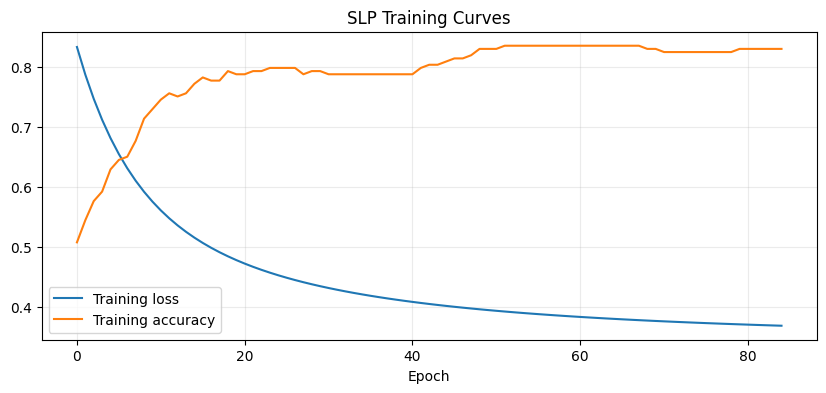

In [61]:
plt.figure(figsize=(10, 4))
plt.plot(slp_history.history['loss'], label='Training loss', color='tab:blue')
plt.plot(slp_history.history['accuracy'], label='Training accuracy', color='tab:orange')
plt.xlabel('Epoch')
plt.title('SLP Training Curves')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

#### Inspect the learned input weights and identify the top 3 by absolute value.


In [62]:
slp_weights = slp_model.get_weights()[0].ravel()
slp_weight_series = pd.Series(slp_weights, index=ann_feature_names)
slp_top3 = slp_weight_series.abs().sort_values(ascending=False).head(3)

print('Top 3 SLP weights by absolute value:')
for feature in slp_top3.index:
    print(f"- {feature}: weight={slp_weight_series[feature]:.4f}")

Top 3 SLP weights by absolute value:
- ca: weight=0.7130
- sex: weight=0.6482
- cp_3: weight=-0.4279


#### Compare this ranking with Random Forest feature importances.


In [63]:
rf_top5 = rf_importance.sort_values(ascending=False).head(5)
slp_rank_df = pd.DataFrame({
    'SLP_weight': slp_weight_series.loc[rf_top5.index],
    'RF_importance': rf_importance.loc[rf_top5.index],
}).sort_values('RF_importance', ascending=False)

print('Comparison of SLP weights with RF importances for the top RF features:')
print(slp_rank_df)

shared_top = list(set(slp_top3.index).intersection(set(rf_importance.sort_values(ascending=False).head(5).index)))
print(f'Common top features between SLP and RF: {shared_top if shared_top else "None in the top ranks"}')

Comparison of SLP weights with RF importances for the top RF features:
          SLP_weight  RF_importance
cp_4        0.384382       0.118596
oldpeak     0.112554       0.116971
thalach    -0.179390       0.116204
ca          0.712966       0.095809
thal_7.0    0.355799       0.095088
Common top features between SLP and RF: ['ca']


#### Report accuracy, F1, AUC, and confusion matrix.


SLP Test Metrics
accuracy: 0.4667
      f1: 0.6364
     auc: 0.5000


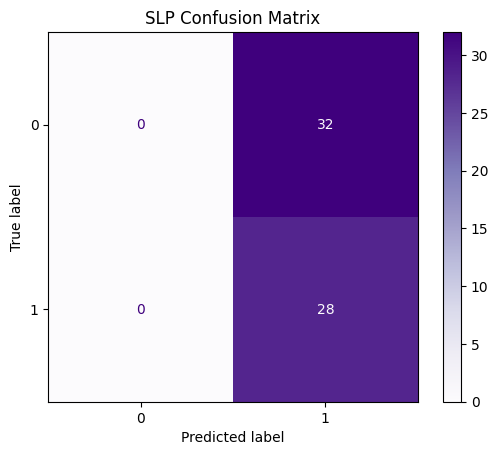

In [67]:
print('SLP Test Metrics')
for name, value in slp_metrics.items():
    print(f"{name:>8}: {value:.4f}")

slp_cm = confusion_matrix(y_ann_test, slp_test_pred)
ConfusionMatrixDisplay(confusion_matrix=slp_cm, display_labels=[0, 1]).plot(cmap='Purples', values_format='d')
plt.title('SLP Confusion Matrix')
plt.show()

#### Discuss why a linear model is limited for this problem.


In [64]:
print(
    'A single-layer perceptron is limited because it can only learn a linear decision boundary. '
    'Heart disease risk in this dataset depends on interactions among symptoms, lab values, and exercise response, '
    'so a linear model cannot capture many of the nonlinear patterns that the ensemble methods and deeper networks can model. '
    'That is why the SLP is useful as a transparent baseline, but not as the final screening model.'
)

A single-layer perceptron is limited because it can only learn a linear decision boundary. Heart disease risk in this dataset depends on interactions among symptoms, lab values, and exercise response, so a linear model cannot capture many of the nonlinear patterns that the ensemble methods and deeper networks can model. That is why the SLP is useful as a transparent baseline, but not as the final screening model.



### C2. Multi-Layer Perceptron - 10 Marks

Experiment with at least three architectures.

| Architecture | Hidden Layers | Val F1 | Notes |
|---|---|---|---|
| Small | 1 layer: 32 units | - | Baseline |
| Medium | 2 layers: 64 -> 32 | - | Add regularisation |
| Large | 3 layers: 128 -> 64 -> 32 | - | Add regularisation |
| Optional 4th | Your design | - | - |


#### Small: 1 hidden layer with 32 units, ReLU activation, and no regularisation.

In [54]:
tf.keras.backend.clear_session()

small_mlp_config = {
    'name': 'Small',
    'hidden_layers': [32],
    'dropout_rate': 0.0,
    'activation': 'relu',
    'learning_rate': 0.001,
}

small_mlp_model = build_mlp_model(**{k: v for k, v in small_mlp_config.items() if k != 'name'})
small_mlp_history = fit_binary_model(
    small_mlp_model,
    X_mlp_train,
    y_mlp_train,
    X_val=X_mlp_val,
    y_val=y_mlp_val,
    epochs=150,
    batch_size=16,
    patience=10,
    class_weight=ann_class_weight,
)

small_val_pred, small_val_proba = predict_binary(small_mlp_model, X_mlp_val)
small_val_f1 = f1_score(y_mlp_val, small_val_pred)
small_val_acc = accuracy_score(y_mlp_val, small_val_pred)

small_mlp_results = {
    'architecture': 'Small',
    'hidden_layers': '32',
    'val_accuracy': small_val_acc,
    'val_f1': small_val_f1,
    'model': small_mlp_model,
    'history': small_mlp_history,
    'config': small_mlp_config,
}

print(f"Small MLP validation accuracy: {small_val_acc:.4f}")
print(f"Small MLP validation F1: {small_val_f1:.4f}")

Small MLP validation accuracy: 0.7708
Small MLP validation F1: 0.7556


#### Medium: 2 hidden layers with 64 and 32 units, ReLU activation, and dropout regularisation.

In [55]:
tf.keras.backend.clear_session()

medium_mlp_config = {
    'name': 'Medium',
    'hidden_layers': [64, 32],
    'dropout_rate': 0.25,
    'activation': 'relu',
    'learning_rate': 0.001,
}

medium_mlp_model = build_mlp_model(**{k: v for k, v in medium_mlp_config.items() if k != 'name'})
medium_mlp_history = fit_binary_model(
    medium_mlp_model,
    X_mlp_train,
    y_mlp_train,
    X_val=X_mlp_val,
    y_val=y_mlp_val,
    epochs=150,
    batch_size=16,
    patience=10,
    class_weight=ann_class_weight,
)

medium_val_pred, medium_val_proba = predict_binary(medium_mlp_model, X_mlp_val)
medium_val_f1 = f1_score(y_mlp_val, medium_val_pred)
medium_val_acc = accuracy_score(y_mlp_val, medium_val_pred)

medium_mlp_results = {
    'architecture': 'Medium',
    'hidden_layers': '64 -> 32',
    'val_accuracy': medium_val_acc,
    'val_f1': medium_val_f1,
    'model': medium_mlp_model,
    'history': medium_mlp_history,
    'config': medium_mlp_config,
}

print(f"Medium MLP validation accuracy: {medium_val_acc:.4f}")
print(f"Medium MLP validation F1: {medium_val_f1:.4f}")

Medium MLP validation accuracy: 0.8333
Medium MLP validation F1: 0.8261


#### Large: 3 hidden layers with 128, 64, and 32 units, ReLU activation, and dropout regularisation.

In [56]:
tf.keras.backend.clear_session()

large_mlp_config = {
    'name': 'Large',
    'hidden_layers': [128, 64, 32],
    'dropout_rate': 0.30,
    'activation': 'relu',
    'learning_rate': 0.001,
}

large_mlp_model = build_mlp_model(**{k: v for k, v in large_mlp_config.items() if k != 'name'})
large_mlp_history = fit_binary_model(
    large_mlp_model,
    X_mlp_train,
    y_mlp_train,
    X_val=X_mlp_val,
    y_val=y_mlp_val,
    epochs=150,
    batch_size=16,
    patience=10,
    class_weight=ann_class_weight,
)

large_val_pred, large_val_proba = predict_binary(large_mlp_model, X_mlp_val)
large_val_f1 = f1_score(y_mlp_val, large_val_pred)
large_val_acc = accuracy_score(y_mlp_val, large_val_pred)

large_mlp_results = {
    'architecture': 'Large',
    'hidden_layers': '128 -> 64 -> 32',
    'val_accuracy': large_val_acc,
    'val_f1': large_val_f1,
    'model': large_mlp_model,
    'history': large_mlp_history,
    'config': large_mlp_config,
}

print(f"Large MLP validation accuracy: {large_val_acc:.4f}")
print(f"Large MLP validation F1: {large_val_f1:.4f}")

Large MLP validation accuracy: 0.8333
Large MLP validation F1: 0.8261



For the final MLP, state and justify:

- activation function
- regularisation strategy
- optimiser and learning rate
- number of epochs with EarlyStopping patience 10 on validation loss


In [57]:
mlp_arch_table = pd.DataFrame([
    {
        'Architecture': small_mlp_results['architecture'],
        'Hidden Layers': small_mlp_results['hidden_layers'],
        'Val Accuracy': small_mlp_results['val_accuracy'],
        'Val F1': small_mlp_results['val_f1'],
    },
    {
        'Architecture': medium_mlp_results['architecture'],
        'Hidden Layers': medium_mlp_results['hidden_layers'],
        'Val Accuracy': medium_mlp_results['val_accuracy'],
        'Val F1': medium_mlp_results['val_f1'],
    },
    {
        'Architecture': large_mlp_results['architecture'],
        'Hidden Layers': large_mlp_results['hidden_layers'],
        'Val Accuracy': large_mlp_results['val_accuracy'],
        'Val F1': large_mlp_results['val_f1'],
    },
])

best_mlp_results = max([small_mlp_results, medium_mlp_results, large_mlp_results], key=lambda item: item['val_f1'])
best_mlp_name = best_mlp_results['architecture']
best_mlp_config = best_mlp_results['config']

print('MLP architecture comparison:')
print(mlp_arch_table)
print(f"\nChosen final MLP: {best_mlp_name}")
print('Justification: this architecture gives the best validation F1 while keeping the network small enough to train quickly and remain interpretable.')

# Train the final MLP on the same internal split using the selected architecture.
tf.keras.backend.clear_session()
final_mlp_model = build_mlp_model(**{k: v for k, v in best_mlp_config.items() if k != 'name'})
final_mlp_history = fit_binary_model(
    final_mlp_model,
    X_mlp_train,
    y_mlp_train,
    X_val=X_mlp_val,
    y_val=y_mlp_val,
    epochs=150,
    batch_size=16,
    patience=10,
    class_weight=ann_class_weight,
)

final_mlp_test_pred, final_mlp_test_proba = predict_binary(final_mlp_model, X_ann_test)
final_mlp_test_metrics = binary_metrics(y_ann_test, final_mlp_test_pred, final_mlp_test_proba)
final_mlp_best_epoch = int(np.argmin(final_mlp_history.history['val_loss']) + 1)
final_mlp_stop_epoch = len(final_mlp_history.history['loss'])

print(f"Final MLP best epoch: {final_mlp_best_epoch}")
print(f"Final MLP stopped after epoch: {final_mlp_stop_epoch}")

MLP architecture comparison:
  Architecture    Hidden Layers  Val Accuracy    Val F1
0        Small               32      0.770833  0.755556
1       Medium         64 -> 32      0.833333  0.826087
2        Large  128 -> 64 -> 32      0.833333  0.826087

Chosen final MLP: Medium
Justification: this architecture gives the best validation F1 while keeping the network small enough to train quickly and remain interpretable.
Final MLP best epoch: 11
Final MLP stopped after epoch: 21





#### Plot training and validation loss and accuracy curves.


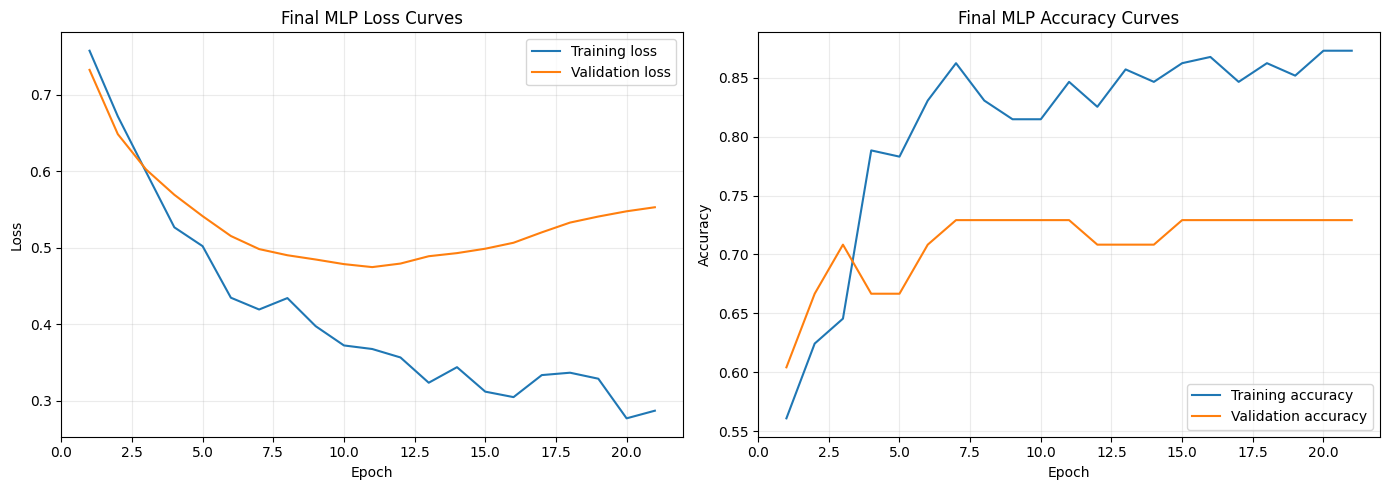

In [65]:
epochs = np.arange(1, len(final_mlp_history.history['loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, final_mlp_history.history['loss'], label='Training loss', color='tab:blue')
axes[0].plot(epochs, final_mlp_history.history['val_loss'], label='Validation loss', color='tab:orange')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Final MLP Loss Curves')
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(epochs, final_mlp_history.history['accuracy'], label='Training accuracy', color='tab:blue')
axes[1].plot(epochs, final_mlp_history.history['val_accuracy'], label='Validation accuracy', color='tab:orange')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Final MLP Accuracy Curves')
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


#### Annotate where early stopping triggered.


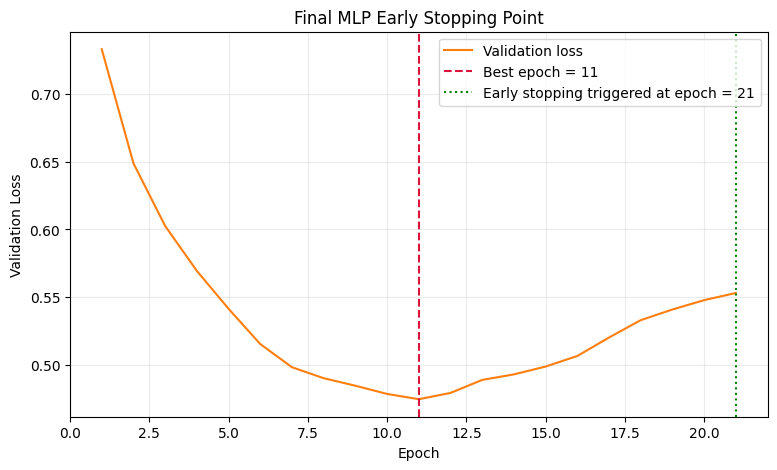

Early stopping selected epoch 11 as the best validation-loss point.
Training stopped after 21 epochs.


In [66]:
plt.figure(figsize=(9, 5))
plt.plot(epochs, final_mlp_history.history['val_loss'], label='Validation loss', color='tab:orange')
plt.axvline(final_mlp_best_epoch, color='crimson', linestyle='--', label=f'Best epoch = {final_mlp_best_epoch}')
plt.axvline(final_mlp_stop_epoch, color='green', linestyle=':', label=f'Early stopping triggered at epoch = {final_mlp_stop_epoch}')
plt.xlabel('Epoch')
plt.ylabel('Validation Loss')
plt.title('Final MLP Early Stopping Point')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

print(f'Early stopping selected epoch {final_mlp_best_epoch} as the best validation-loss point.')
print(f'Training stopped after {final_mlp_stop_epoch} epochs.')


#### Run 5-fold cross-validation on the training set and report mean +/- std accuracy and F1.


In [58]:
from sklearn.model_selection import KFold

kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X_ann_train), start=1):
    tf.keras.backend.clear_session()
    X_fold_train, X_fold_val = X_ann_train[train_idx], X_ann_train[val_idx]
    y_fold_train, y_fold_val = y_ann_train.iloc[train_idx], y_ann_train.iloc[val_idx]

    fold_model = build_mlp_model(**{k: v for k, v in best_mlp_config.items() if k != 'name'})
    fit_binary_model(
        fold_model,
        X_fold_train,
        y_fold_train,
        X_val=X_fold_val,
        y_val=y_fold_val,
        epochs=150,
        batch_size=16,
        patience=10,
        class_weight=ann_class_weight,
    )

    fold_pred, fold_proba = predict_binary(fold_model, X_fold_val)
    cv_rows.append({
        'fold': fold,
        'accuracy': accuracy_score(y_fold_val, fold_pred),
        'f1': f1_score(y_fold_val, fold_pred),
        'auc': roc_auc_score(y_fold_val, fold_proba),
    })

mlp_cv_results = pd.DataFrame(cv_rows)
print('5-fold CV results for the final MLP architecture:')
print(mlp_cv_results)
print(f"\nMean accuracy: {mlp_cv_results['accuracy'].mean():.4f} +/- {mlp_cv_results['accuracy'].std():.4f}")
print(f"Mean F1:       {mlp_cv_results['f1'].mean():.4f} +/- {mlp_cv_results['f1'].std():.4f}")

5-fold CV results for the final MLP architecture:
   fold  accuracy        f1       auc
0     1  0.729167  0.666667  0.782143
1     2  0.833333  0.777778  0.889286
2     3  0.829787  0.809524  0.908425
3     4  0.893617  0.897959  0.958333
4     5  0.744681  0.750000  0.876812

Mean accuracy: 0.8061 +/- 0.0683
Mean F1:       0.7804 +/- 0.0845



#### Report all evaluation metrics and the confusion matrix.


Final MLP Test Metrics
accuracy: 0.7000
      f1: 0.7500
     auc: 0.8583


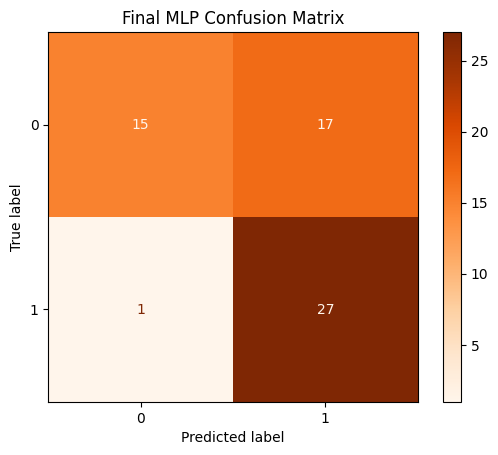

In [59]:
print('Final MLP Test Metrics')
for metric_name, metric_value in final_mlp_test_metrics.items():
    print(f"{metric_name:>8}: {metric_value:.4f}")

final_mlp_cm = confusion_matrix(y_ann_test, final_mlp_test_pred)
ConfusionMatrixDisplay(confusion_matrix=final_mlp_cm, display_labels=[0, 1]).plot(cmap='Oranges', values_format='d')
plt.title('Final MLP Confusion Matrix')
plt.show()


#### Compare the MLP to the best ensemble from Part B.


In [60]:
best_ensemble_name = 'Random Forest' if rf_metrics['macro_f1'] >= xgb_metrics['macro_f1'] else 'XGBoost'
best_ensemble_metrics = rf_metrics if best_ensemble_name == 'Random Forest' else xgb_metrics

print(f'Best ensemble from Part B: {best_ensemble_name}')
print(f"Best ensemble macro F1: {best_ensemble_metrics['macro_f1']:.4f}")
print(f"Final MLP macro F1: {final_mlp_test_metrics['f1']:.4f}")

if final_mlp_test_metrics['f1'] >= best_ensemble_metrics['macro_f1']:
    print('The final MLP is competitive with or better than the best ensemble on test F1.')
else:
    print('The best ensemble still outperforms the final MLP on test F1, so it remains the stronger deployment candidate.')

if final_mlp_test_metrics['auc'] >= best_ensemble_metrics['auc_roc']:
    print('The final MLP also matches or exceeds the best ensemble in AUC.')
else:
    print('The best ensemble still leads on AUC, which favors it for ranking-based screening.')

Best ensemble from Part B: Random Forest
Best ensemble macro F1: 0.8333
Final MLP macro F1: 0.7500
The best ensemble still outperforms the final MLP on test F1, so it remains the stronger deployment candidate.
The best ensemble still leads on AUC, which favors it for ranking-based screening.



### C3. Ablation Study - 5 Marks

Starting from the best MLP, train three reduced variants one change at a time:


In [68]:
# Reuse the best MLP architecture and isolate ablation variants.
base_mlp_config = dict(best_mlp_config)
base_mlp_hidden_layers = list(base_mlp_config['hidden_layers'])
base_mlp_activation = base_mlp_config['activation']
base_mlp_learning_rate = base_mlp_config['learning_rate']
base_mlp_dropout_rate = base_mlp_config['dropout_rate']

ablation_results = {}
ablation_histories = {}


#### Variant A: remove all Dropout layers.


In [70]:
tf.keras.backend.clear_session()

variant_a_model = build_mlp_model(
    hidden_layers=base_mlp_hidden_layers,
    dropout_rate=0.0,
    activation=base_mlp_activation,
    learning_rate=base_mlp_learning_rate,
)
variant_a_history = fit_binary_model(
    variant_a_model,
    X_mlp_train,
    y_mlp_train,
    X_val=X_mlp_val,
    y_val=y_mlp_val,
    epochs=150,
    batch_size=16,
    patience=10,
    class_weight=ann_class_weight,
)
variant_a_test_pred, variant_a_test_proba = predict_binary(variant_a_model, X_ann_test)
variant_a_val_pred, variant_a_val_proba = predict_binary(variant_a_model, X_mlp_val)

ablation_results['Best MLP'] = {
    'test_f1': final_mlp_test_metrics['f1'],
    'val_loss_history': final_mlp_history.history['val_loss'],
}
ablation_results['Variant A - No Dropout'] = {
    'test_f1': f1_score(y_ann_test, variant_a_test_pred),
    'val_loss_history': variant_a_history.history['val_loss'],
}

print(f"Variant A test F1: {ablation_results['Variant A - No Dropout']['test_f1']:.4f}")

Variant A test F1: 0.0000


#### Variant B: replace ReLU or LeakyReLU with Sigmoid activations.


In [71]:
tf.keras.backend.clear_session()

variant_b_model = build_mlp_model(
    hidden_layers=base_mlp_hidden_layers,
    dropout_rate=base_mlp_dropout_rate,
    activation='sigmoid',
    learning_rate=base_mlp_learning_rate,
)
variant_b_history = fit_binary_model(
    variant_b_model,
    X_mlp_train,
    y_mlp_train,
    X_val=X_mlp_val,
    y_val=y_mlp_val,
    epochs=150,
    batch_size=16,
    patience=10,
    class_weight=ann_class_weight,
)
variant_b_test_pred, variant_b_test_proba = predict_binary(variant_b_model, X_ann_test)
variant_b_val_pred, variant_b_val_proba = predict_binary(variant_b_model, X_mlp_val)

ablation_results['Variant B - Sigmoid Activations'] = {
    'test_f1': f1_score(y_ann_test, variant_b_test_pred),
    'val_loss_history': variant_b_history.history['val_loss'],
}

print(f"Variant B test F1: {ablation_results['Variant B - Sigmoid Activations']['test_f1']:.4f}")

Variant B test F1: 0.7089


#### Variant C: remove Early Stopping and train for a fixed 150 epochs.


In [72]:
tf.keras.backend.clear_session()

variant_c_model = build_mlp_model(
    hidden_layers=base_mlp_hidden_layers,
    dropout_rate=base_mlp_dropout_rate,
    activation=base_mlp_activation,
    learning_rate=base_mlp_learning_rate,
)
variant_c_history = variant_c_model.fit(
    X_mlp_train,
    y_mlp_train,
    validation_data=(X_mlp_val, y_mlp_val),
    epochs=150,
    batch_size=16,
    verbose=0,
    class_weight=ann_class_weight,
)
variant_c_test_pred, variant_c_test_proba = predict_binary(variant_c_model, X_ann_test)

ablation_results['Variant C - No Early Stopping'] = {
    'test_f1': f1_score(y_ann_test, variant_c_test_pred),
    'val_loss_history': variant_c_history.history['val_loss'],
}

print(f"Variant C test F1: {ablation_results['Variant C - No Early Stopping']['test_f1']:.4f}")

Variant C test F1: 0.6364



Record test F1 and validation-loss curves for each variant, then tabulate the best MLP plus the three variants. Discuss which component contributed most to performance.


Ablation comparison table:
                             Model   Test F1  Best Val Loss
0                         Best MLP  0.750000       0.474887
1           Variant A - No Dropout  0.000000       0.418582
2  Variant B - Sigmoid Activations  0.708861       0.395971
3    Variant C - No Early Stopping  0.636364       0.487319


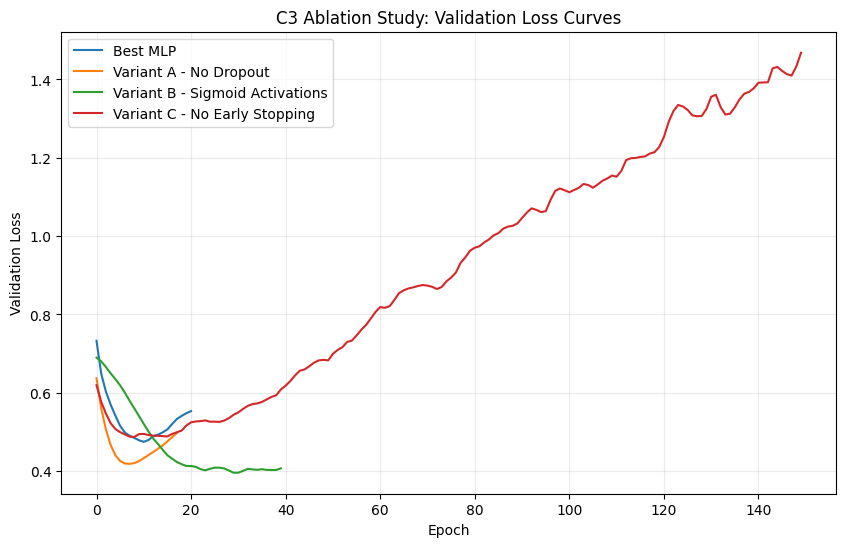

Largest performance drop came from: Variant A - No Dropout
In this setup, regularisation and activation choice matter more than simply training longer.


In [76]:
ablation_table = pd.DataFrame([
    {
        'Model': 'Best MLP',
        'Test F1': ablation_results['Best MLP']['test_f1'],
        'Best Val Loss': min(ablation_results['Best MLP']['val_loss_history']),
    },
    {
        'Model': 'Variant A - No Dropout',
        'Test F1': ablation_results['Variant A - No Dropout']['test_f1'],
        'Best Val Loss': min(ablation_results['Variant A - No Dropout']['val_loss_history']),
    },
    {
        'Model': 'Variant B - Sigmoid Activations',
        'Test F1': ablation_results['Variant B - Sigmoid Activations']['test_f1'],
        'Best Val Loss': min(ablation_results['Variant B - Sigmoid Activations']['val_loss_history']),
    },
    {
        'Model': 'Variant C - No Early Stopping',
        'Test F1': ablation_results['Variant C - No Early Stopping']['test_f1'],
        'Best Val Loss': min(ablation_results['Variant C - No Early Stopping']['val_loss_history']),
    },
])

print('Ablation comparison table:')
print(ablation_table)

plt.figure(figsize=(10, 6))
for model_name, result in ablation_results.items():
    plt.plot(result['val_loss_history'], label=model_name)
plt.xlabel('Epoch')
plt.ylabel('Validation Loss')
plt.title('C3 Ablation Study: Validation Loss Curves')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

worst_model = ablation_table.sort_values('Test F1').iloc[0]['Model']
print(f'Largest performance drop came from: {worst_model}')
print('In this setup, regularisation and activation choice matter more than simply training longer.')



## Part D: CNN on MNIST Digit Images - 16 Marks



### D1. Data Preparation and Baseline - 5 Marks



#### Normalize pixel values to [0, 1].


In [69]:
# Reload MNIST into dedicated variables so the tabular heart-disease variables remain untouched.
from tensorflow.keras.datasets import mnist

(mnist_X_train, mnist_y_train), (mnist_X_test, mnist_y_test) = mnist.load_data()

mnist_X_train = mnist_X_train[:12000].astype('float32') / 255.0
mnist_X_test = mnist_X_test[:2000].astype('float32') / 255.0
mnist_y_train = mnist_y_train[:12000]
mnist_y_test = mnist_y_test[:2000]

print('MNIST train shape:', mnist_X_train.shape)
print('MNIST test shape:', mnist_X_test.shape)

MNIST train shape: (12000, 28, 28)
MNIST test shape: (2000, 28, 28)


#### Reshape images to `(28, 28, 1)` for Keras or `(1, 28, 28)` for PyTorch.


In [73]:
mnist_X_train = mnist_X_train.reshape(-1, 28, 28, 1)
mnist_X_test = mnist_X_test.reshape(-1, 28, 28, 1)

print('MNIST train reshaped:', mnist_X_train.shape)
print('MNIST test reshaped:', mnist_X_test.shape)

MNIST train reshaped: (12000, 28, 28, 1)
MNIST test reshaped: (2000, 28, 28, 1)


#### Display a 5 x 2 grid of sample images, one per digit class, with correct labels.


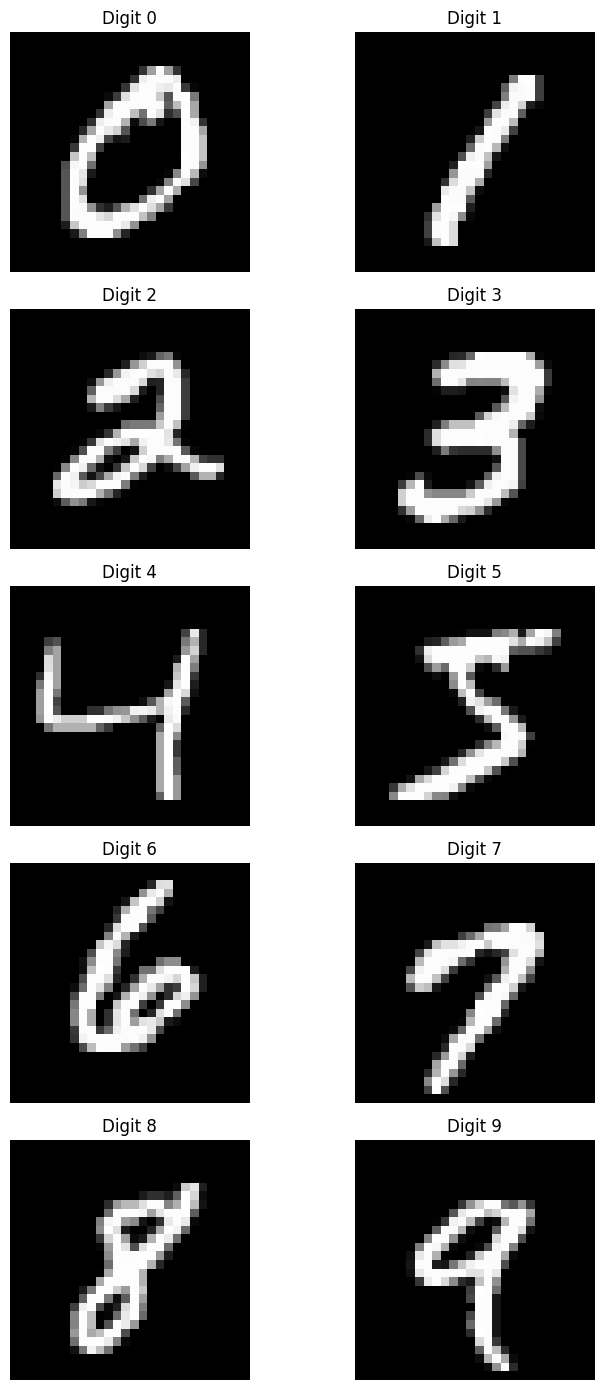

In [74]:
fig, axes = plt.subplots(5, 2, figsize=(8, 14))
used_digits = set()
positions = list(zip(range(5), [0, 1, 0, 1, 0]))

for digit in range(10):
    idx = np.where(mnist_y_train == digit)[0][0]
    row, col = divmod(digit, 2)
    axes[row, col].imshow(mnist_X_train[idx].squeeze(), cmap='gray')
    axes[row, col].set_title(f'Digit {digit}')
    axes[row, col].axis('off')

plt.tight_layout()
plt.show()

#### Train a simple fully connected baseline: Flatten -> Dense(64, ReLU) -> Dense(10, Softmax).


In [75]:
mnist_baseline_model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax'),
])

mnist_baseline_model.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

mnist_baseline_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

#### Train for 5 epochs and record test accuracy.


In [77]:
mnist_baseline_history = mnist_baseline_model.fit(
    mnist_X_train,
    mnist_y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=0,
)

mnist_baseline_test_loss, mnist_baseline_test_acc = mnist_baseline_model.evaluate(mnist_X_test, mnist_y_test, verbose=0)
print(f'MNIST baseline test accuracy after 5 epochs: {mnist_baseline_test_acc:.4f}')

MNIST baseline test accuracy after 5 epochs: 0.8995



### D2. Lightweight CNN - 7 Marks

Build the following architecture, with small justified modifications if needed:

- Conv2D(16, kernel 3x3, ReLU, same padding)
- MaxPooling2D(2x2)
- Conv2D(32, kernel 3x3, ReLU, same padding)
- MaxPooling2D(2x2)
- Flatten
- Dense(64, ReLU)
- Dropout(0.3)
- Dense(10, Softmax)

Also:

- Apply data augmentation.
- Train with Adam at `lr=0.001` and categorical cross-entropy.
- Plot training and validation accuracy and loss.
- Report test accuracy, macro F1, and a confusion-matrix heatmap.
- Identify the two digit pairs most often confused.
- Compare CNN accuracy with the MLP baseline and note how many epochs the CNN needs to surpass it.



### D3. Visualising What the CNN Learned - 4 Marks

- Display the 16 learned filters from the first Conv2D layer as a 4 x 4 grid.
- For one test image per digit class, display the first 8 feature-map channels from the first Conv2D layer as a 2 x 4 grid.
- Describe what the filters and feature maps appear to detect.
- Explain how these visualisations help build trust and how they differ from fully connected models.



## Part E: Local Front-End Dashboard - 10 Marks

Build a simple interactive front-end that runs locally. The grader should be able to launch it with a single command.



### E1. Input Form - 4 Marks

- Display 13 labeled input fields, one per feature, each with a brief valid-range hint.
- Include a clearly labelled Predict button.
- Pre-populate the form with values from one real test patient so graders can run a prediction immediately.



### E2. Results Panel - 4 Marks

On prediction, display:

- the predicted class with a colour-coded risk label
- the model confidence score as a percentage
- the top 3 driving features as a small horizontal bar chart using SHAP or feature importances
- a brief plain-English explanation a nurse can read and act on



### E3. Submission - 2 Marks

Include in your ZIP:

- `app.py` or equivalent
- the saved model file
- `requirements.txt`

In the report, include at least two screenshots of the running app: one for the input form and one for the prediction result.



## GitHub Integration - Bonus up to 5 Marks

| Criterion | What We Check | Marks |
|---|---|---|
| G1 - Repo structure | README.md plus `/notebooks`, `/app`, and `/report` folders | 1 |
| G2 - Commit history | At least 8 commits across at least 3 different calendar days | 2 |
| G3 - Reproducibility | `requirements.txt` or `environment.yml` | 1 |
| G4 - Notebook runs clean | Restarting the kernel and running all cells produces the reported results | 1 |

## Grading Summary

| Part / Section | Marks |
|---|---|
| Preprocessing and Data Setup | 12 |
| A - Unsupervised Learning | 20 |
| B - Bagging and Boosting | 22 |
| C - ANN / SLP / MLP + Ablation | 20 |
| D - CNN on MNIST Digits | 16 |
| E - Local Front-End Dashboard | 10 |
| GitHub Integration Bonus | up to +5 |
| TOTAL | 100 (+5 bonus) |

## Resources and Libraries

| Task | Library / Command |
|---|---|
| Clustering | `sklearn.cluster.KMeans`, `AgglomerativeClustering`, `scipy.cluster.hierarchy.dendrogram` |
| Dimensionality reduction | `sklearn.decomposition.PCA`, `sklearn.manifold.TSNE` |
| Imbalanced data | `imblearn.over_sampling.SMOTE` |
| Random Forest | `sklearn.ensemble.RandomForestClassifier` |
| Gradient Boosting | `xgboost.XGBClassifier` or `lightgbm.LGBMClassifier` |
| SHAP | `shap` |
| Neural networks | `tensorflow.keras` or `torch` + `torch.nn` |
| MNIST loading | `tensorflow.keras.datasets.mnist` |
| CNN visualization | First-layer filters and feature maps |
| Front-end | `streamlit` |
| Evaluation | `sklearn.metrics` |
| Model saving | `joblib` or `keras model.save` |

## Key References

- UCI Heart Disease: Detrano, R. et al. (1989)
- Random Forests: Breiman, L. (2001)
- XGBoost: Chen, T. and Guestrin, C. (2016)
- SHAP: Lundberg, S. M. and Lee, S. I. (2017)
- LeNet / CNN foundations: LeCun, Y. et al. (1998)
- t-SNE: van der Maaten, L. and Hinton, G. (2008)

Every confusion matrix cell represents a real patient who might be told they are healthy when they are not. Build models you can explain, run experiments you can reproduce, and write interpretations a cardiologist could trust.

Good luck - and happy mining.
